# NBA Stats Analysis
This is an NBA players exploratory analysis to experiment with different visualizations and find various insights about basketball statistics leaders. It covers every NBA regular season from 1955-56 to 2022-23.

Firstly, we need to get the data from [basketball reference](https://www.basketball-reference.com/). We used a script to get the data. The script is based on [data.world](https://data.world/etocco/nba-player-stats). We define the range of seasons we want and the folder where the scraped tables are saved, so that the notebook can be re-run without scraping the website again.

In [1]:
import os
import time
import warnings
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

years = range(1955,2023) #the range of seasons we want (1955-56 to 2022-23)
DATA_DIR = 'data' #folder where the scraped tables are saved

Next we define some helper functions to read the html tables. Every player has a unique id on basketball-reference (it is part of the link to his page), which we keep next to his name, because different players can have the same name. Every table is saved as a csv file in the `data` folder the first time it is scraped, and it is read from there afterwards.

In [2]:
def read_bbref_table(url):
    table = pd.read_html(url, extract_links='body')[0] #every cell is read as a (text, link) pair
    if isinstance(table.columns, pd.MultiIndex):
        table = table.droplevel(0, axis = 1)
    player_links = table['Player'].str[1]
    table = table.apply(lambda column: column.str[0]).replace('', np.nan) #keeping only the text of every cell
    table['player_id'] = player_links.str.extract(r'/players/\w/(\w+)\.html', expand=False)
    return table

def load_or_scrape(name, scrape):
    path = os.path.join(DATA_DIR, name + '.csv')
    if os.path.exists(path):
        return pd.read_csv(path, dtype=str) #reading everything as text, exactly like the scraped tables
    table = scrape()
    os.makedirs(DATA_DIR, exist_ok=True)
    table.to_csv(path, index=False)
    return table

def scrape_seasons(table_type):
    dictionary_data = {}
    for year in years:
        url = f"https://www.basketball-reference.com/leagues/NBA_{year+1}_{table_type}.html"
        dictionary_data[year] = read_bbref_table(url)
        dictionary_data[year]['Season'] = str(year)+'-'+str(year + 1)[-2:] #e.g. 1997-98
        time.sleep(5) #pausing the script for 5 seconds to avoid getting error message "too many requests" from server
    return pd.concat(dictionary_data, ignore_index=True)

Now we read the per-game table and the totals table of every season. Each row of the per-game table contains the per-game averages of one player in one season, while the totals table contains his total numbers for that season. We use the per-game data for the season analysis and the totals for the career statistics. The first time, scraping takes around 12 minutes because of the 5 second pause between the requests.

In [3]:
per_game_raw = load_or_scrape('per_game', lambda: scrape_seasons('per_game'))
totals_raw = load_or_scrape('totals', lambda: scrape_seasons('totals'))

Next we remove the rows with no player information (e.g. the `League Average` row at the end of every table) and keep the columns we need. A player who was traded during a season has one row for each team and one row with his combined stats, which basketball-reference labels `2TM`, `3TM` etc. depending on the number of teams. We label all those combined rows as `TOT` (total).

In [4]:
table_columns = ['Rk','Player','player_id','Pos','Age','Tm','G','GS','MP','FG','FGA','FG%','3P','3PA','3P%','2P','2PA','2P%',
                 'eFG%','FT','FTA','FT%','ORB','DRB','TRB','AST','STL','BLK','TOV','PF','PTS','Season']

def clean_season_table(table):
    table = table.loc[table.player_id.notna()].copy() #removes rows with no valuable information
    table = table.rename(columns={'Team':'Tm'})
    table['Tm'] = table['Tm'].replace(r'^\dTM$', 'TOT', regex=True) #combined row of a traded player
    return table[table_columns].reset_index(drop=True)

data = clean_season_table(per_game_raw)
totals = clean_season_table(totals_raw)

Next we read the mvp data table

In [5]:
mvp_table = load_or_scrape('mvp', lambda: read_bbref_table('https://www.basketball-reference.com/awards/mvp.html'))
mvp_table['MVP'] = True

Now we merge the mvp data with the rest, using the season and the player id.

In [6]:
data = data.merge(mvp_table[['Season','player_id','MVP']], on=['Season','player_id'], how='left')
data['MVP'] = data['MVP'].notna() #players that are not in the mvp table did not win the award that season

Transforming the numeric data columns from text to integer or float:

In [7]:
column_names_numeric = ['Age','G','GS','MP','FG','FGA','FG%','3P','3PA','3P%','2P','2PA','2P%','eFG%',
            'FT','FTA','FT%','ORB','DRB','TRB','AST','BLK','STL','TOV','PF','PTS']
data[column_names_numeric] = data[column_names_numeric].apply(pd.to_numeric, errors='coerce')
totals[column_names_numeric] = totals[column_names_numeric].apply(pd.to_numeric, errors='coerce')

Some statistics were only officially recorded from a certain season on: steals and blocks since 1973-74, turnovers since 1977-78 and games started since 1981-82 (3-pointers since 1979-80, when the 3-point line was introduced). Basketball-reference also has numbers for a few players in some earlier seasons, but because they only cover some of the players, we remove them so that all players are compared on the same basis:

In [8]:
official_since = {'STL':'1973-74', 'BLK':'1973-74', 'TOV':'1977-78', 'GS':'1981-82'} #first season each statistic was officially recorded
for table in [data, totals]:
    for statistic, season in official_since.items():
        table.loc[table.Season < season, statistic] = np.nan

Each row contains stats of one player for one particular regular season. However, one player could have three or more rows of data for one particular season if he was traded mid-season and played for more than one team (one row for his time with the first team, one row for his time with the team he got transferred to and one row for the averages of both together).

We print a sample of the data to see the different columns and information contained in each row of this dataset

In [9]:
pd.set_option('display.max_columns', None) #setting to print all the columns
data.sample(5, random_state=0)

,Rk,Player,player_id,Pos,Age,Tm,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Season,MVP
6890,317,Kenny Natt,nattke01,SG,26,UTA,4,0.0,3.3,0.5,1.3,0.400,0.0,0.0,NaN,0.5,1.3,0.400,0.400,0.5,1.0,0.500,0.3,0.3,0.5,0.0,0.3,0.0,0.8,0.5,1.5,1984-85,False
2379,67,Kevin Loughery,loughke01,SG,31,BAL,2,NaN,21.0,2.0,8.5,0.235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.5,4.0,0.625,NaN,NaN,2.5,4.0,NaN,NaN,NaN,2.5,6.5,1971-72,False
4340,270,Cliff Pondexter,pondecl01,PF,23,CHI,44,NaN,12.1,0.8,1.9,0.435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3,0.5,0.700,0.8,2.1,3.0,2.0,0.4,0.3,0.7,1.5,2.0,1977-78,False
7810,134,Craig Hodges,hodgecr01,SG,27,MIL,43,0.0,22.9,3.6,8.0,0.449,1.3,2.7,0.466,2.3,5.3,0.441,0.529,0.7,0.9,0.821,0.3,0.8,1.1,2.5,0.7,0.0,1.1,1.9,9.2,1987-88,False
15756,242,Elden Campbell,campbel01,C,35,DET,65,27.0,13.7,2.1,4.8,0.439,0.0,0.0,NaN,2.1,4.8,0.439,0.439,1.3,1.9,0.685,0.8,2.4,3.2,0.7,0.3,0.8,1.0,2.1,5.6,2003-04,False


After checking the column `Rk`, which stands for Rank, we find out that it does not give much information. It is just the position of the player in the table of that season, which basketball-reference sorts by points per game. For example, `Bob Pettit` is rank 1 for the 1955-56 season because he scored the most points per game that season (25.7). A traded player has the same rank in all of his rows.

In [10]:
data.loc[data.Rk=='1'].head()

,Rk,Player,player_id,Pos,Age,Tm,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Season,MVP
0,1,Bob Pettit,pettibo01,C,23,STL,72,NaN,38.8,9.0,20.9,0.429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.7,10.5,0.736,NaN,NaN,16.2,2.6,NaN,NaN,NaN,2.8,25.7,1955-56,True
106,1,Paul Arizin,arizipa01,SF,28,PHW,71,NaN,39.0,8.6,20.4,0.422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.3,10.0,0.829,NaN,NaN,7.9,2.1,NaN,NaN,NaN,3.9,25.6,1956-57,False
221,1,George Yardley,yardlge01,SF,29,DET,72,NaN,39.5,9.3,22.6,0.414,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.1,11.2,0.811,NaN,NaN,10.7,1.3,NaN,NaN,NaN,3.1,27.8,1957-58,False
332,1,Bob Pettit,pettibo01,PF,26,STL,72,NaN,39.9,10.0,22.8,0.438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.3,12.2,0.759,NaN,NaN,16.4,3.1,NaN,NaN,NaN,2.8,29.2,1958-59,True
442,1,Wilt Chamberlain,chambwi01,C,23,PHW,72,NaN,46.4,14.8,32.1,0.461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,13.8,0.582,NaN,NaN,27.0,2.3,NaN,NaN,NaN,2.1,37.6,1959-60,True


As a result, we drop the column `Rk`:

In [11]:
data = data.drop(columns=['Rk'])
totals = totals.drop(columns=['Rk'])

We will remove all the players that averaged less than 1 minute played

In [12]:
data = data.loc[(data.MP >= 1)].copy()

Here we can see the description of the abbreviation columns, as seen in [basketball-reference.com](https://www.basketball-reference.com/leagues/NBA_2022_per_game.html):
* Pos -- Position
* Age -- Player's age on February 1 of the season
* Tm -- Team (`TOT` when the row combines the stats of more than one team)
* G -- Games
* GS -- Games Started
* MP -- Minutes Played Per Game
* FG -- Field Goals Per Game
* FGA -- Field Goal Attempts Per Game
* FG% -- Field Goal Percentage
* 3P -- 3-Point Field Goals Per Game
* 3PA -- 3-Point Field Goal Attempts Per Game
* 3P% -- 3-Point Field Goal Percentage
* 2P -- 2-Point Field Goals Per Game
* 2PA -- 2-Point Field Goal Attempts Per Game
* 2P% -- 2-Point Field Goal Percentage
* eFG% -- Effective Field Goal Percentage. This statistic adjusts for the fact that a 3-point field goal is worth one more point than a 2-point field goal.
* FT -- Free Throws Per Game
* FTA -- Free Throw Attempts Per Game
* FT% -- Free Throw Percentage
* ORB -- Offensive Rebounds Per Game
* DRB -- Defensive Rebounds Per Game
* TRB -- Total Rebounds Per Game
* AST -- Assists Per Game
* STL -- Steals Per Game
* BLK -- Blocks Per Game
* TOV -- Turnovers Per Game
* PF -- Personal Fouls Per Game
* PTS -- Points Per Game

As mentioned, some statistics are empty in the early seasons because they were not recorded yet (offensive and defensive rebounds are also recorded since 1973-74).

Now we will check the shape of the dataframe, (number of rows, number of columns):

In [13]:
data.shape

(27845, 32)

Next we will use the command `describe()` to check basic statistics of every column

In [14]:
data.describe()

,Age,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
count,27845.000000,27845.000000,22419.000000,27845.000000,27845.000000,27845.000000,27720.000000,23139.000000,23139.000000,19356.000000,23139.000000,23139.000000,22948.000000,23024.000000,27845.000000,27845.000000,26709.000000,25009.000000,25009.000000,27845.000000,27845.000000,25009.000000,25009.000000,23857.000000,27845.000000,27845.000000
mean,26.589298,49.382726,22.615505,20.091370,3.183045,7.074904,0.436269,0.472605,1.373590,0.262128,2.591841,5.391465,0.466017,0.471974,1.594498,2.141110,0.724244,1.013111,2.503403,3.676825,1.888271,0.661054,0.402739,1.233831,1.959332,8.351381
std,3.920784,26.649603,27.967606,10.217601,2.314855,4.820674,0.098429,0.655540,1.736633,0.171476,2.057122,4.046883,0.108671,0.104639,1.450428,1.844109,0.143898,0.861486,1.825380,2.785350,1.813670,0.477257,0.494943,0.830903,0.898774,6.129134
min,18.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,25.000000,0.000000,11.600000,1.400000,3.300000,0.399000,0.000000,0.000000,0.154000,1.000000,2.300000,0.428000,0.438000,0.600000,0.800000,0.663000,0.400000,1.200000,1.700000,0.600000,0.300000,0.100000,0.600000,1.300000,3.600000
50%,26.000000,55.000000,7.000000,19.300000,2.600000,5.900000,0.441000,0.100000,0.600000,0.308000,2.000000,4.200000,0.473000,0.481000,1.200000,1.600000,0.750000,0.800000,2.100000,3.000000,1.300000,0.600000,0.200000,1.000000,1.900000,6.800000
75%,29.000000,75.000000,42.000000,28.500000,4.500000,9.900000,0.484000,0.800000,2.300000,0.368000,3.700000,7.600000,0.513000,0.520000,2.200000,2.900000,0.814000,1.400000,3.300000,4.900000,2.600000,0.900000,0.500000,1.700000,2.600000,11.800000
max,44.000000,88.000000,83.000000,48.500000,20.000000,39.500000,1.000000,5.300000,13.200000,1.000000,13.200000,27.000000,1.000000,1.500000,10.600000,17.000000,1.000000,7.200000,13.700000,27.200000,14.500000,3.700000,6.000000,5.700000,6.000000,50.400000


Even with these basic statistics we can find some interesting conclusions:
* The youngest player that played at least 1 game in any season was 18 years old and the oldest 44 years old
* The most games played in one season by one player were 88 games
* The most average minutes played per game for one season were 48.5
* The most average field goal attempts per game for one season were 39.5
* The most average 3 point attempts per game for one season were 13.2
* The most average free throw attempts per game for one season were 17
* The highest average rebounds per game for one season were 27.2
* Some maximums, like the 100% field goal percentage or the 150% effective field goal percentage, come from players that took only a handful of shots. This is why we will use minimum requirements (e.g. games played) for the leaderboards later on.

Hiding warnings for different plots afterwards

In [15]:
warnings.filterwarnings(action='ignore')

For the season analysis we only want one row per player per season. For players that played for more than one team in a season, we keep the row with the most games played, which is the `TOT` row with his combined stats. We use the player id instead of the name, because different players can have the same name (e.g. two different players named Eddie Johnson played in the NBA during the 1980s).

In [16]:
data_no_duplicates = data.sort_values(by=['G'], ascending=False)\
                         .drop_duplicates(subset=['Season','player_id']).sort_index()

## Age
Now we will see the youngest players that played at least one game in one season:

In [17]:
data_no_duplicates.loc[data_no_duplicates.Age == data_no_duplicates.Age.min()][['Player','Season','Age']].reset_index(drop=True)

,Player,Season,Age
0,Bill Willoughby,1975-76,18
1,Kobe Bryant,1996-97,18
2,Jermaine O'Neal,1996-97,18
3,Tracy McGrady,1997-98,18
4,Al Harrington,1998-99,18
5,Bruno Šundov,1998-99,18
6,Maciej Lampe,2003-04,18
7,Darko Miličić,2003-04,18
8,Andris Biedriņš,2004-05,18
9,Amir Johnson,2005-06,18


Now we will check the oldest players:

In [18]:
data_no_duplicates.loc[data_no_duplicates.Age == data_no_duplicates.Age.max()][['Player','Season','Age']].reset_index(drop=True)

,Player,Season,Age
0,Kevin Willis,2006-07,44


Last we will check the average age of an nba player for those seasons. We use the data with one row per player per season, so that players who played for more than one team in a season are only counted once:

In [19]:
age_data = data_no_duplicates[['Season','player_id','Age']].copy()

Now we can see the average age:

In [20]:
age_data.Age.mean()

np.float64(26.506673105628238)

We will also check the average of the average ages per season. Here every season counts the same, no matter how many players played in it:

In [21]:
age_data.groupby(['Season'])['Age'].mean().mean()

np.float64(26.408744855186914)

Now we will also analyze the evolution of the average age of an nba player over the years

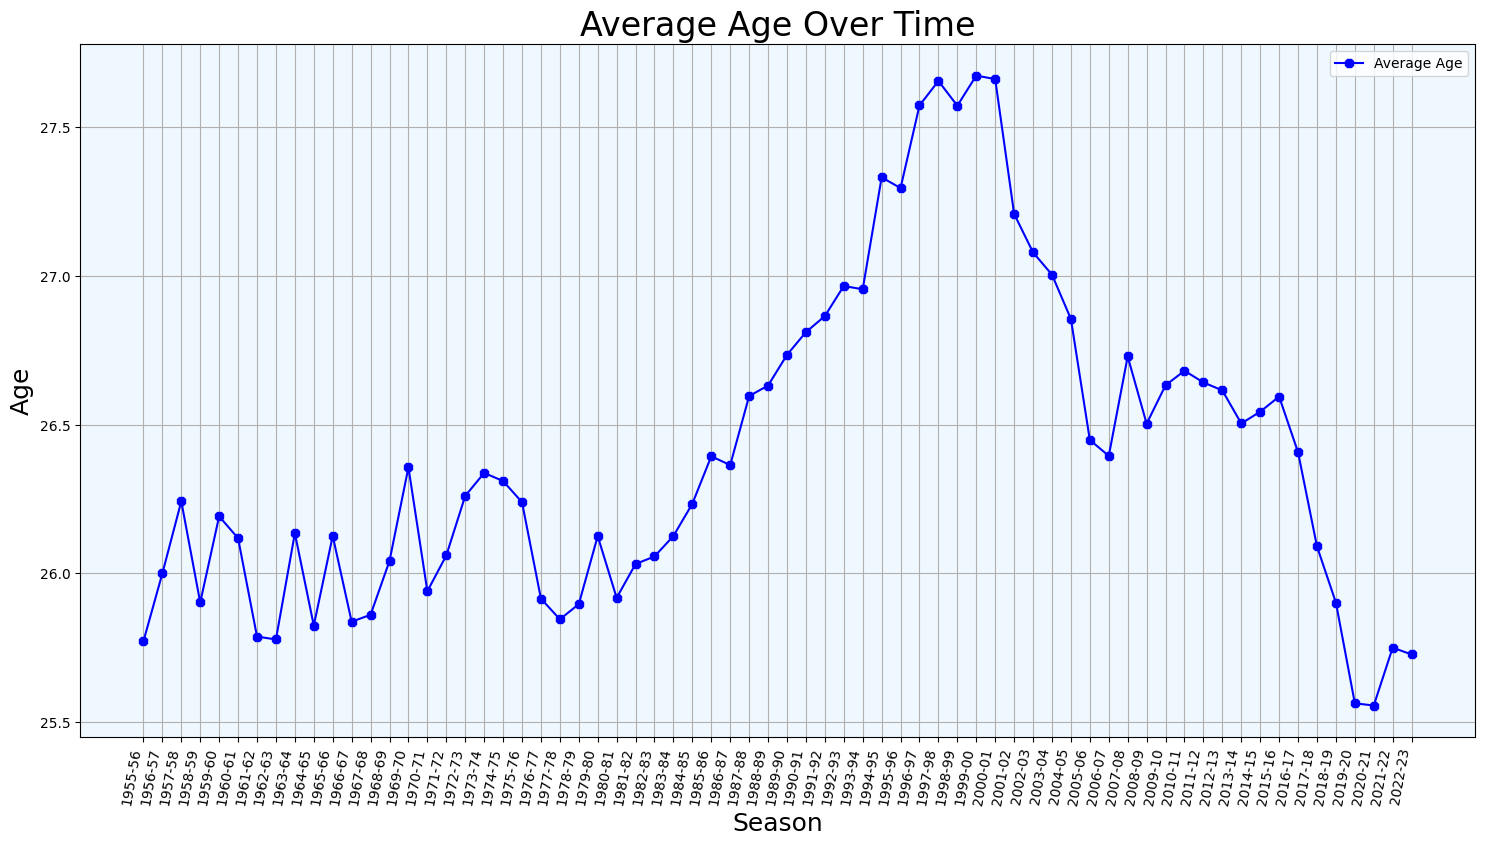

In [22]:
fig, ax = plt.subplots(figsize=(18,9))
grouped_age_per_season = age_data.groupby(['Season'])['Age'].mean().reset_index()
grouped_age_per_season.plot(ax=ax, marker="8", label="Average Age over time", color='blue')
plt.title('Average Age Over Time', fontdict ={'size': 24}, loc='center')
plt.ylabel('Age', fontdict ={'size': 18})
plt.xlabel('Season',fontdict ={'size': 18})
ax.grid(which='both') #add grid
plt.xticks(rotation=80, ha='right') #rotate xticks
ax.set_facecolor("aliceblue") #setting background color
ax.set_xticklabels(grouped_age_per_season.Season) #setting xticks labels
ax.set_xticks(np.arange((grouped_age_per_season.shape[0]))) #setting range of xticks
plt.legend(loc="upper right", labels=['Average Age'])
plt.show()

#### Conclusion
The average age kept rising from the early 1980s until it peaked at the end of the 1990s (27.7 years in 1999-00 and 2000-01), the era of the traditional big men and post-up focused offence. After that period the average keeps dropping, and it hit its all-time low in 2020-21 (25.6 years, practically the same as in 2019-20), with a small increase in the last two seasons. The NBA is becoming a young man's league, since players consistently join the league as 19-year-olds after just spending one year in college or overseas. Also, the fact that the game is becoming quicker, with more possessions and more transition 3-point shots, makes it tougher for older players to stick around for long. Part of the latest drop also comes from a roster rule: since 2017-18 every team can sign two-way players (mostly young players who split their time between the NBA and the G League).

Next, we will calculate for every season the percentage of players that are younger than 24 years old (23 or younger). For that we count the players under 24 of every season and all the players of every season. Then we divide the first with the second to calculate the percentage:

In [23]:
freq_young_perseason = age_data[['Season','Age']].loc[age_data.Age < 24].groupby(['Season']).count().reset_index()
#finding the frequencies of players under 24 years old
freq_young_perseason = freq_young_perseason.rename(columns= {'Age':'Freq_under_24'}) #renaming
freq_players_perseason = age_data[['Season','Age']].groupby(['Season']).count().reset_index()
freq_players_perseason = freq_players_perseason.rename(columns= {'Age':'Freq'}) #renaming
freq_season_age = freq_players_perseason.merge(freq_young_perseason,on= 'Season') #merging dfs
freq_season_age['percentage_under_24'] = freq_season_age['Freq_under_24'] / freq_season_age['Freq']

Now we can visualize the results. The percentage of players under 24 hit its lowest point in 1994-95 (14.5%) and has more than doubled since then, reaching 37.4% in 2020-21:

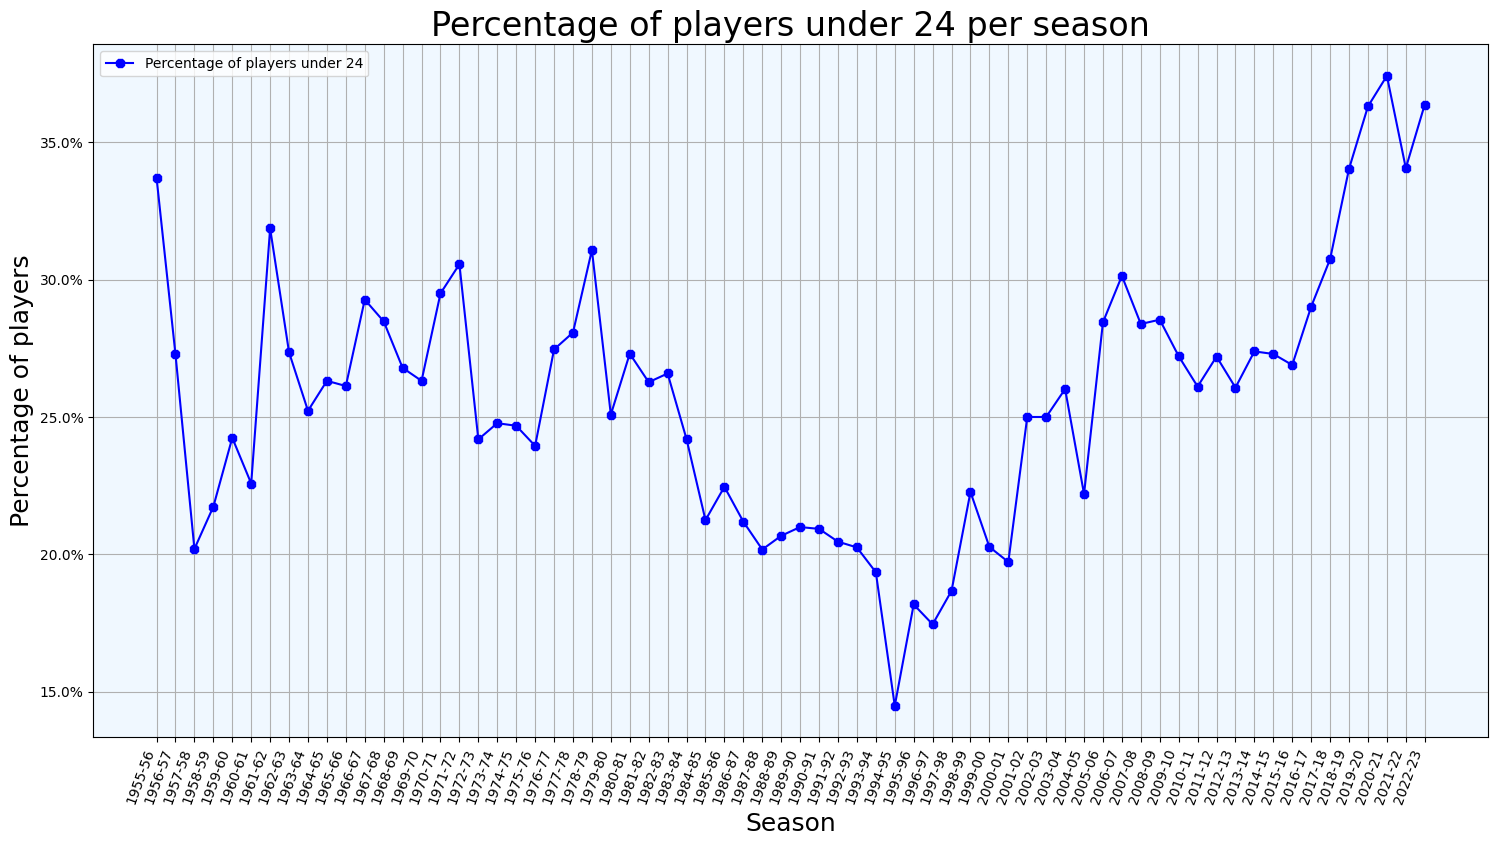

In [24]:
fig, ax = plt.subplots(figsize=(18,9))
freq_season_age[['Season','percentage_under_24']].plot(ax=ax, marker="8",
                                                       label="Percentage of players under 24 per season",
                                                       color='blue')
plt.title('Percentage of players under 24 per season', fontdict ={'size': 24}, loc='center')
plt.ylabel('Percentage of players', fontdict ={'size': 18})
plt.xlabel('Season',fontdict ={'size': 18})
ax.grid(which='both') #add grid
plt.xticks(rotation=70, ha='right') #rotate xticks
ax.set_facecolor("aliceblue") #setting background color
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)) #showing the y axis as percentages
ax.set_xticklabels(freq_season_age.Season) #setting xticks labels
ax.set_xticks(np.arange((freq_season_age.shape[0]))) #setting range of xticks
plt.legend(loc="upper left", labels=['Percentage of players under 24'])
plt.show()

#### Conclusion
Again this plot confirms that the NBA is becoming a younger league. The game is becoming faster, with more shots early on the shot-clock (e.g. transition three-pointers which were a big no-no in the past), leading to more possessions, and the athletic ability and stamina of young players fit this kind of basketball style perfectly. The jump after 2017-18 is also related to the two-way contracts, which added roster spots that are mostly filled by young players. The dip in 2021-22 is explained by the many veterans that were signed on short hardship contracts that season, to replace the players that entered the COVID-19 health and safety protocols.

## Number of players per season
Now we will create a graph showing the number of players per season

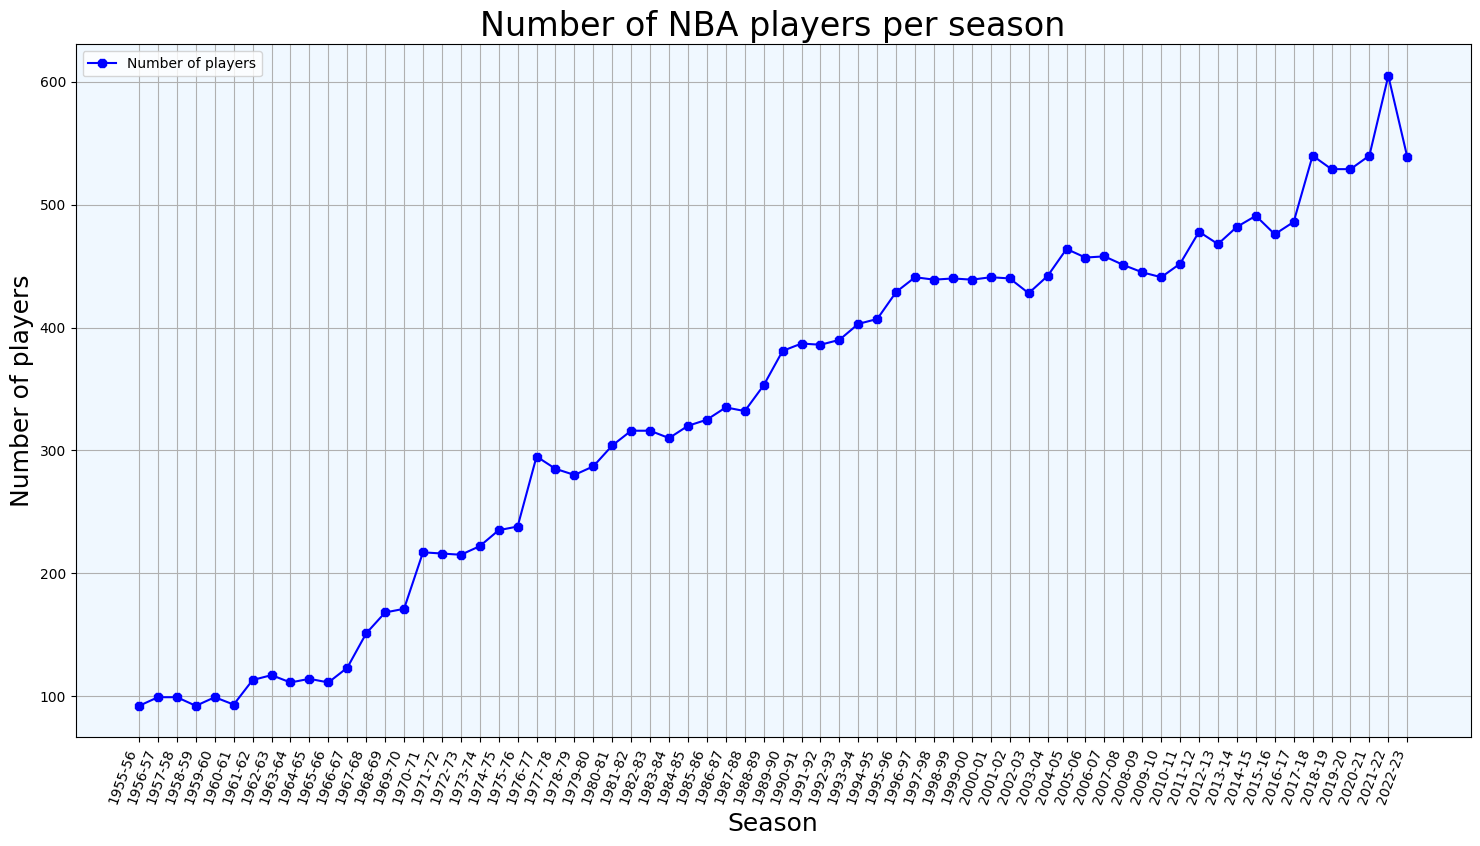

In [25]:
fig, ax = plt.subplots(figsize=(18,9))
freq_players_perseason.plot(ax=ax, marker="8",
                                label="Number of NBA players per season",
                                color='blue')
plt.title('Number of NBA players per season', fontdict ={'size': 24}, loc='center')
plt.ylabel('Number of players', fontdict ={'size': 18})
plt.xlabel('Season',fontdict ={'size': 18})
ax.grid(which='both') #add grid
plt.xticks(rotation=70, ha='right') #rotate xticks
ax.set_facecolor("aliceblue") #setting background color
ax.set_xticklabels(freq_players_perseason.Season) #setting xticks labels
ax.set_xticks(np.arange((freq_players_perseason.shape[0]))) #setting range of xticks
plt.legend(loc="upper left", labels=['Number of players'])
plt.show()

The number of NBA players has risen from 92 in 1955-56 to more than 500 today. The main reason is the expansion of the league from 8 teams in 1955-56 to 30 teams since 2004-05: the biggest jumps of the plot match the seasons when new teams joined (e.g. the late 1960s, 1970-71, the merger with the ABA in 1976-77, 1988-89 to 1989-90 and 1995-96). More recently, the two-way contracts (since 2017-18) gave every team more roster spots, and the peak of 605 players in 2021-22 is due to the hardship contracts signed during the COVID-19 outbreaks of that season. On top of that, teams are more willing to give opportunities to players through 10-day contracts and G League call-ups, and the game keeps becoming more global, which makes the competition to enter the league even fiercer.

## Teams
Something great about the data is that there is a team value: `TOT` which means that the player has played for more than 1 team. As we can see in the following example, Justise Winslow played for two teams in the 2021-22 season. However, there are 3 rows for that player. One row is for his time with the LA Clippers, one with the Portland Trail Blazers and one with the stats of both together.

In [26]:
data.loc[(data.Player =='Justise Winslow') & (data.Season =='2021-22')]

,Player,player_id,Pos,Age,Tm,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Season,MVP
26814,Justise Winslow,winslju01,PF,25,TOT,48,11.0,16.1,2.3,5.4,0.428,0.3,1.4,0.227,2.0,4.0,0.497,0.457,0.8,1.4,0.591,1.0,3.2,4.2,1.8,0.7,0.5,1.0,1.4,5.7,2021-22,False
26815,Justise Winslow,winslju01,PF,25,LAC,37,1.0,13.0,1.7,3.8,0.447,0.1,0.8,0.172,1.6,3.0,0.518,0.465,0.7,1.1,0.610,0.8,2.8,3.6,1.4,0.6,0.5,1.0,1.2,4.2,2021-22,False
26816,Justise Winslow,winslju01,PF,25,POR,11,10.0,26.8,4.3,10.5,0.405,0.9,3.4,0.270,3.4,7.2,0.468,0.448,1.3,2.3,0.560,1.8,4.5,6.3,2.9,1.3,0.6,1.1,1.9,10.7,2021-22,False


## Games played
Now we will find some stats about the games played. Firstly, the players that played the most games in a single season. All those players in those seasons played for more than one team, which is how they played more games than a regular season has


In [27]:
data_no_duplicates.sort_values(by=['G'], ascending=False)[['Player','Season','Tm','G']].head(10).reset_index(drop=True)

,Player,Season,Tm,G
0,Walt Bellamy,1968-69,TOT,88
1,Tom Henderson,1976-77,TOT,87
2,Gar Heard,1975-76,TOT,86
3,McCoy McLemore,1970-71,TOT,86
4,Chris Gatling,1999-00,TOT,85
5,John Tresvant,1967-68,TOT,85
6,Nate Williams,1974-75,TOT,85
7,Shareef Abdur-Rahim,2003-04,TOT,85
8,Theo Ratliff,2003-04,TOT,85
9,Howard Komives,1968-69,TOT,85


Next, we will find the players that have played the most games in their career. For the career statistics we use the totals data. Like with the per-game data, we keep one row per player per season and then add up the seasons of every player. Again we group by the player id, otherwise players with the same name would be added together:

In [28]:
totals_no_duplicates = totals.sort_values(by=['G'], ascending=False)\
                             .drop_duplicates(subset=['Season','player_id']).sort_index()

sum_games_per_player = totals_no_duplicates.groupby('player_id').agg({'Player':'last','G':'sum','GS':'sum'}).reset_index()
sum_games_per_player = sum_games_per_player.sort_values(by=['G'], ascending=False)

Visualizing the results of the top 10 players with the most games played:

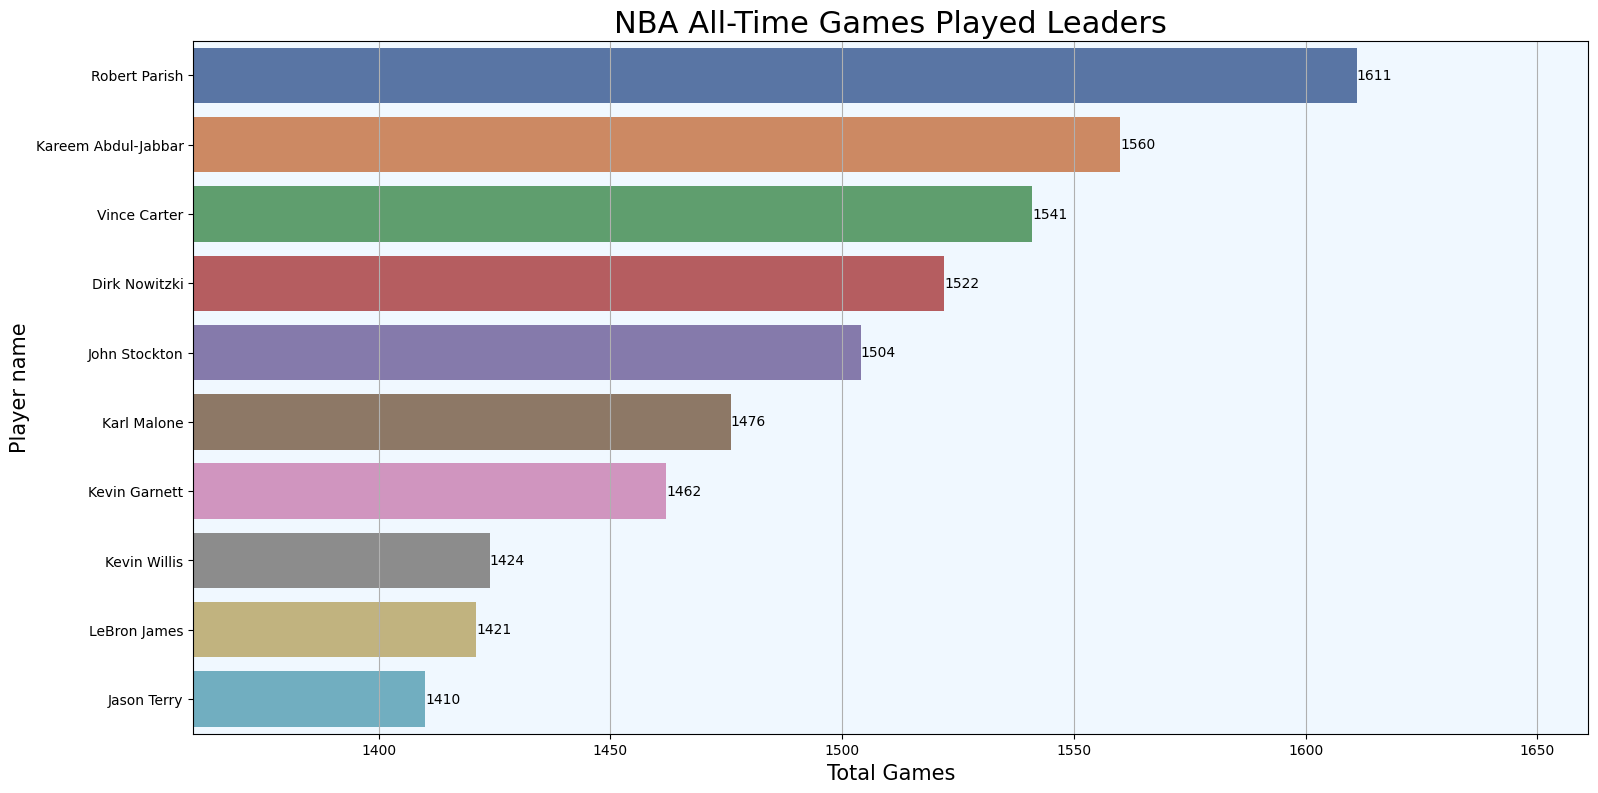

In [29]:
fig_dims = (18, 9) #setting the dimensions of the diagram
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=sum_games_per_player.Player[:10], x=sum_games_per_player.G[:10], palette='deep')
plt.title('NBA All-Time Games Played Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total Games',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.xlim(sum_games_per_player.iloc[9,sum_games_per_player.columns.get_loc('G')] - 50,
        sum_games_per_player.iloc[0,sum_games_per_player.columns.get_loc('G')]+ 50)
#setting x axis ranges close to the top 10 players games played
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Games started
Now we create the same diagram for the games started for each player in their career. Games started are only recorded since the 1981-82 season, so players whose careers started earlier (e.g. Kareem Abdul-Jabbar) are missing some of their starts:

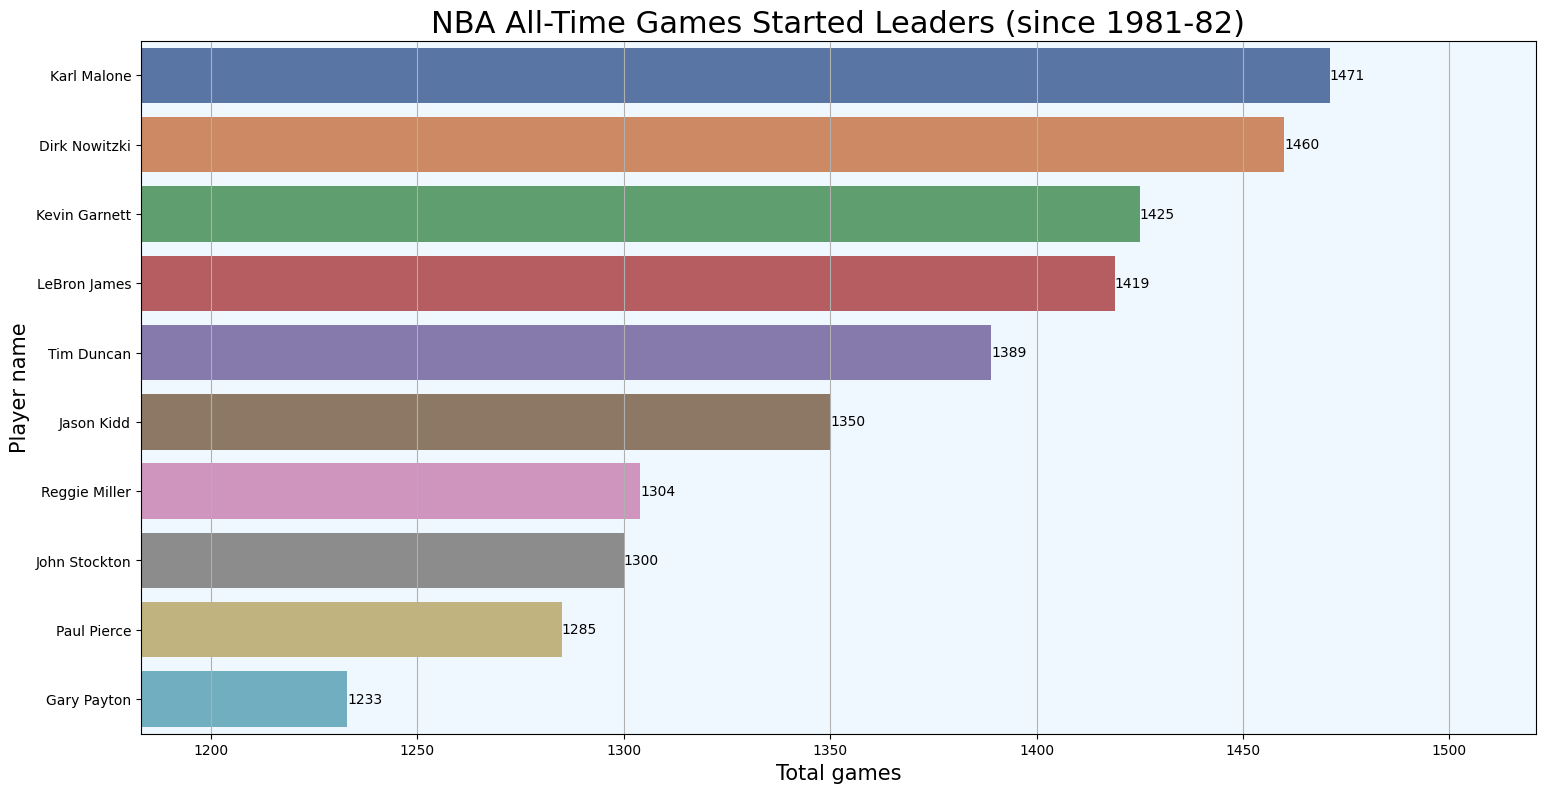

In [30]:
sum_games_per_player = sum_games_per_player.sort_values(by=['GS'], ascending=False) #sorting Df based on games started
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=sum_games_per_player.Player[:10], x=sum_games_per_player.GS[:10], palette='deep')
plt.title('NBA All-Time Games Started Leaders (since 1981-82)', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total games',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.xlim(sum_games_per_player.iloc[9,sum_games_per_player.columns.get_loc('GS')] - 50,
        sum_games_per_player.iloc[0,sum_games_per_player.columns.get_loc('GS')]+ 50)
#setting x axis ranges close to the top 10 players games started
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Points and three point attempts over the years
Next the evolution of three point shooting and points over the seasons. We will read another webpage from basketball-reference with the league averages of every season, which goes back to the first season of the league (1946-47)

In [31]:
season_data = load_or_scrape('league_averages',
                             lambda: pd.read_html('https://www.basketball-reference.com/leagues/NBA_stats_per_game.html')[0]\
                                                        .droplevel(0, axis = 1))
season_data.drop(season_data[season_data['Rk'] == 'Rk'].index, inplace = True) # removes rows with no valuable information
season_data.drop(season_data[season_data['3PA'] == 'Per Game'].index, inplace = True) # removes rows with no valuable information

season_data[['3PA','PTS']] = season_data[['3PA','PTS']].apply(pd.to_numeric, errors='coerce') #transform column to numeric
season_data['3PA'] = season_data['3PA'].fillna(0) #there were no 3-point attempts before the 3-point line

We keep the same seasons as in the player data (until 2022-23):

In [32]:
season_data = season_data.loc[season_data.Season <= '2022-23'].copy()

Now we reverse the rows of the dataframe so that the years are increasing:

In [33]:
season_data = season_data.iloc[::-1].reset_index(drop=True)

Visualizing the results:

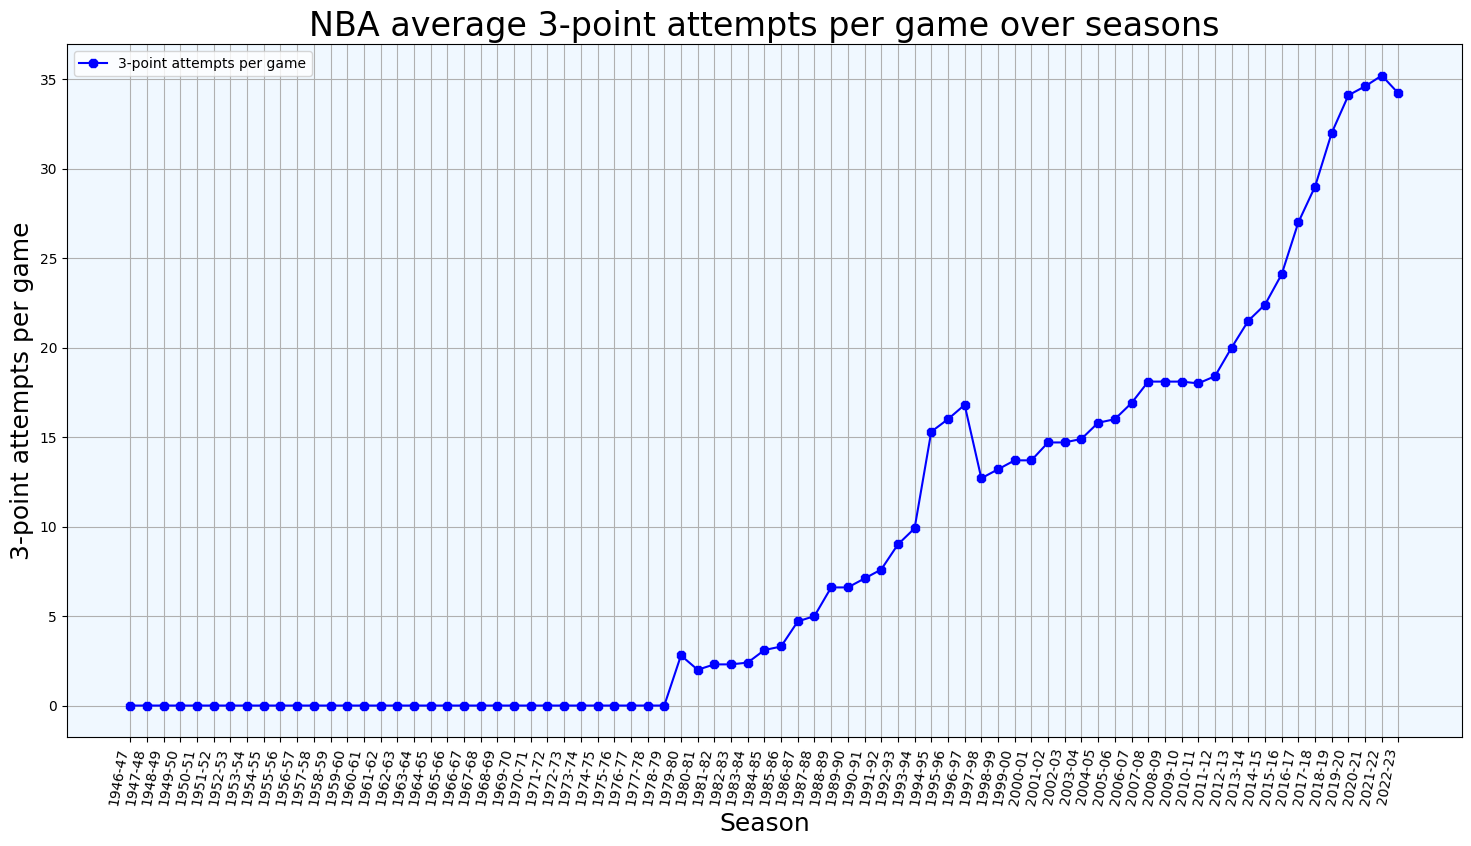

In [34]:
fig, ax = plt.subplots(figsize=(18,9))
season_data[['Season','3PA']].plot(ax=ax, marker="8",
                                label="Three point attempts over time",
                                color='blue')
plt.title('NBA average 3-point attempts per game over seasons', fontdict ={'size': 24}, loc='center')
plt.ylabel('3-point attempts per game', fontdict ={'size': 18})
plt.xlabel('Season',fontdict ={'size': 18})
ax.grid(which='both') #add grid
plt.xticks(rotation=80, ha='right') #rotate xticks
ax.set_facecolor("aliceblue") #setting background color
ax.set_xticklabels(season_data.Season) #setting xticks labels
ax.set_xticks(np.arange((season_data.shape[0]))) #setting range of xticks
plt.legend(loc="upper left", labels=['3-point attempts per game'])
plt.show()

#### Conclusions
It is visible that there were no 3-point shots attempted before the season 1979-80. This makes total sense since the three point line was adopted by the NBA in the 1979-80 season, with Chris Ford scoring the first 3-point shot on the 12th of October 1979. The jump between 1994-95 and 1996-97 and the drop in 1997-98 happened because the NBA moved the 3-point line closer (22 feet all around the court) for those three seasons. Since then, the 3-point shots keep becoming more and more important and vital for a team's success (the Golden State Warriors are a great example of how the 3-Point shot can be deadly against opponents with them winning multiple championships over the last 10 years). In the 2021-22 season there were the most 3-point attempts per game with more than thirty-five 3-point attempts per game. Last but not least, the 3-point shot is becoming so popular that even power-forwards and centers are adding this skill in their repertoire to bring additional value to their team. The 3-point shot threat is a great way to open up space since defenders can not help one pass away from a shooter (since that could lead to an open and easily scored 3-point shot)

Next the average points per game over the seasons

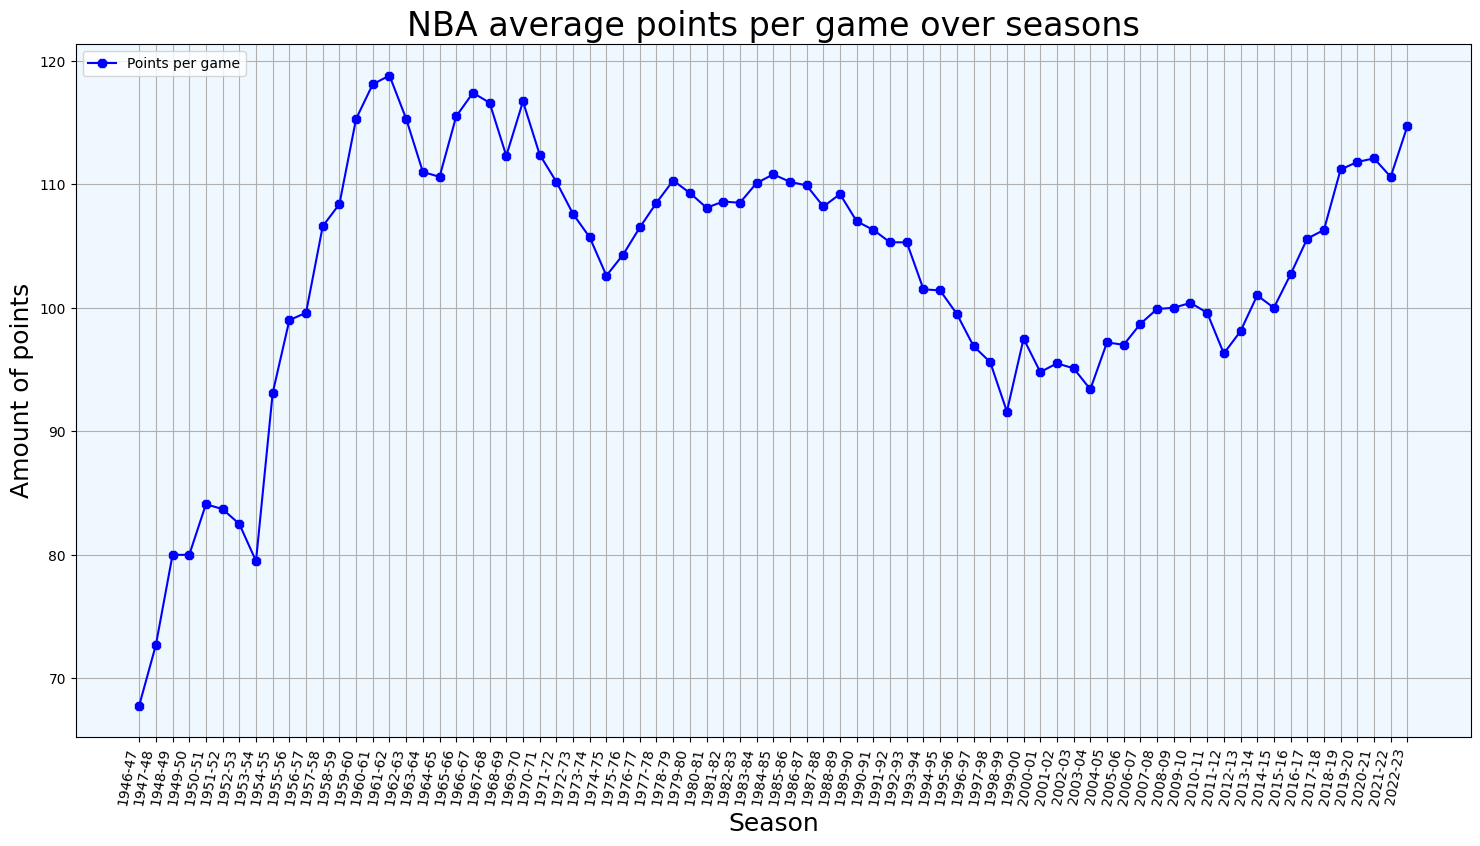

In [35]:
fig, ax = plt.subplots(figsize=(18,9))
season_data[['Season','PTS']].plot(ax=ax, marker="8",
                                label="Points scored over time",
                                color='blue')
plt.title('NBA average points per game over seasons', fontdict ={'size': 24}, loc='center')
plt.ylabel('Amount of points', fontdict ={'size': 18})
plt.xlabel('Season',fontdict ={'size': 18})
ax.grid(which='both') #add grid
plt.xticks(rotation=80, ha='right') #rotate xticks
ax.set_facecolor("aliceblue") #setting background color
ax.set_xticklabels(season_data.Season) #setting xticks labels
ax.set_xticks(np.arange((season_data.shape[0]))) #setting range of xticks
plt.legend(loc="upper left", labels=['Points per game'])
plt.show()

#### Conclusions
Points per game keep increasing from the early 2000s and on, after hitting the lowest point of the shot-clock era (91.6 points) in the 1998-99 lockout season. This is a combination of the offence becoming more deadly and the defence being less able to stop the offence. As already mentioned, the game is becoming quicker with more possessions, more 3-point shots and more early clock offence. On the other side, the rule changes of the 2004-05 season, which banned hand-checking (defenders using their hands to impede the ball-handler), made it much harder for defence to contain the offence.

Despite that, the highest-scoring season of all time was recorded in the 1961-62 season when teams averaged 118.8 points per game.

### MVP awards
Next we will find the players with the most mvp awards. We will use `data_no_duplicates` that contains one row per player per season:

In [36]:
mvpawards_per_player = data_no_duplicates.groupby('player_id').agg({'Player':'last','MVP':'sum'}).reset_index()
#summarizing number of mvp awards per player
mvpawards_per_player = mvpawards_per_player.sort_values(by=['MVP'], ascending=False)

Now we visualize the results:

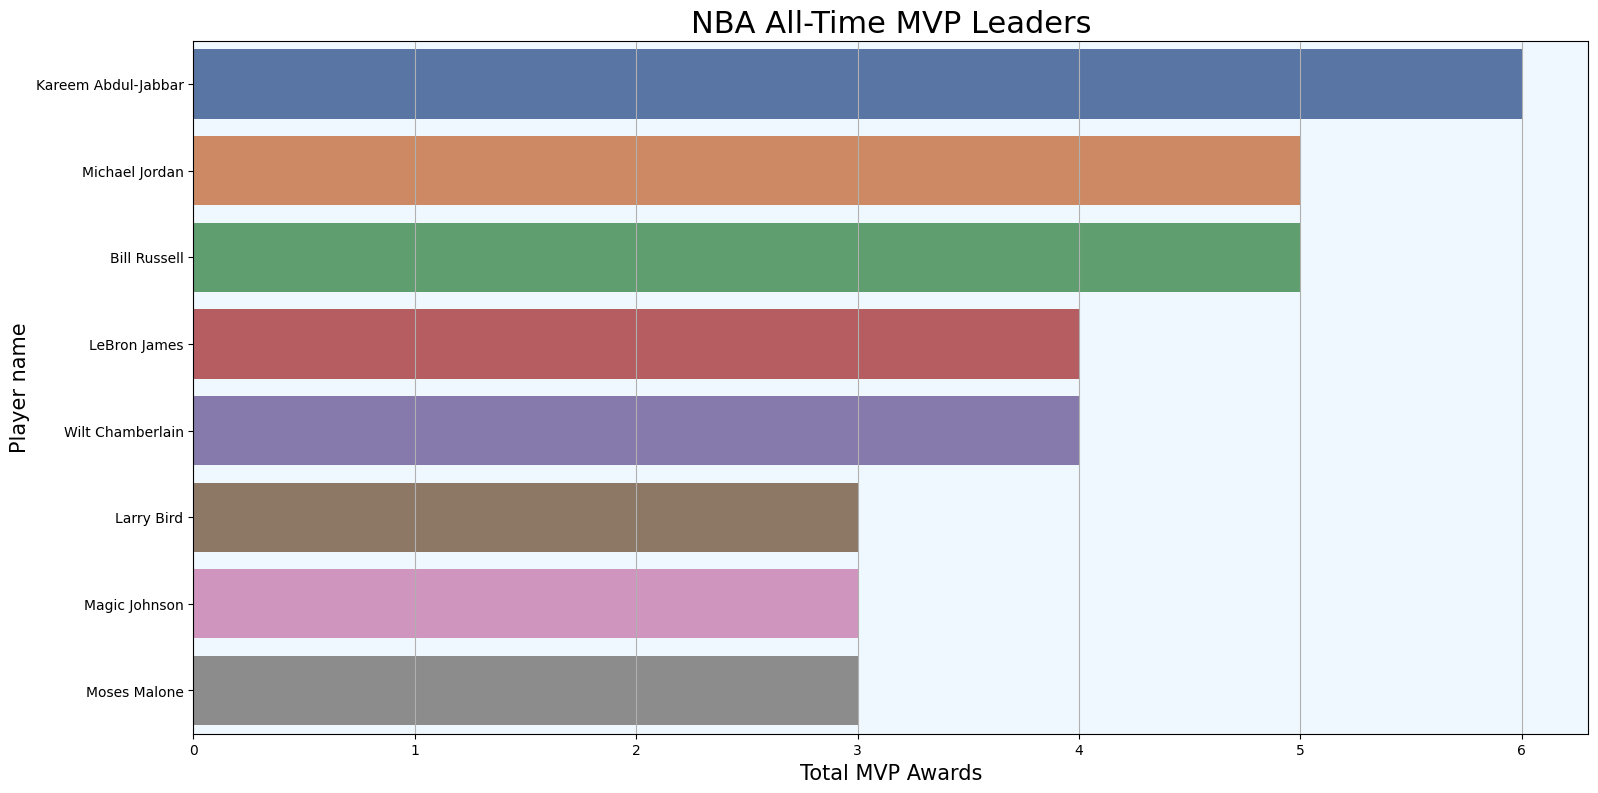

In [37]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=mvpawards_per_player.Player[:8], x=mvpawards_per_player.MVP[:8], palette='deep')
plt.title('NBA All-Time MVP Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total MVP Awards',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.show()

### Championship data
Firstly, we read another webpage to get information on the players with most championships won. This table only includes the players with at least 3 championships:

In [38]:
championships_table = load_or_scrape('championships',
                                     lambda: read_bbref_table('https://www.basketball-reference.com/leaders/most_championships.html'))
championships_table['Player'] = championships_table['Player'].str.strip('*') #removes '*' (Hall of Fame members) from name of players
championships_table.rename(columns={'Count':'championships'}, inplace=True)
championships_table['championships'] = pd.to_numeric(championships_table['championships']) #transform column to numeric

Now we will visualize the NBA championship leaders

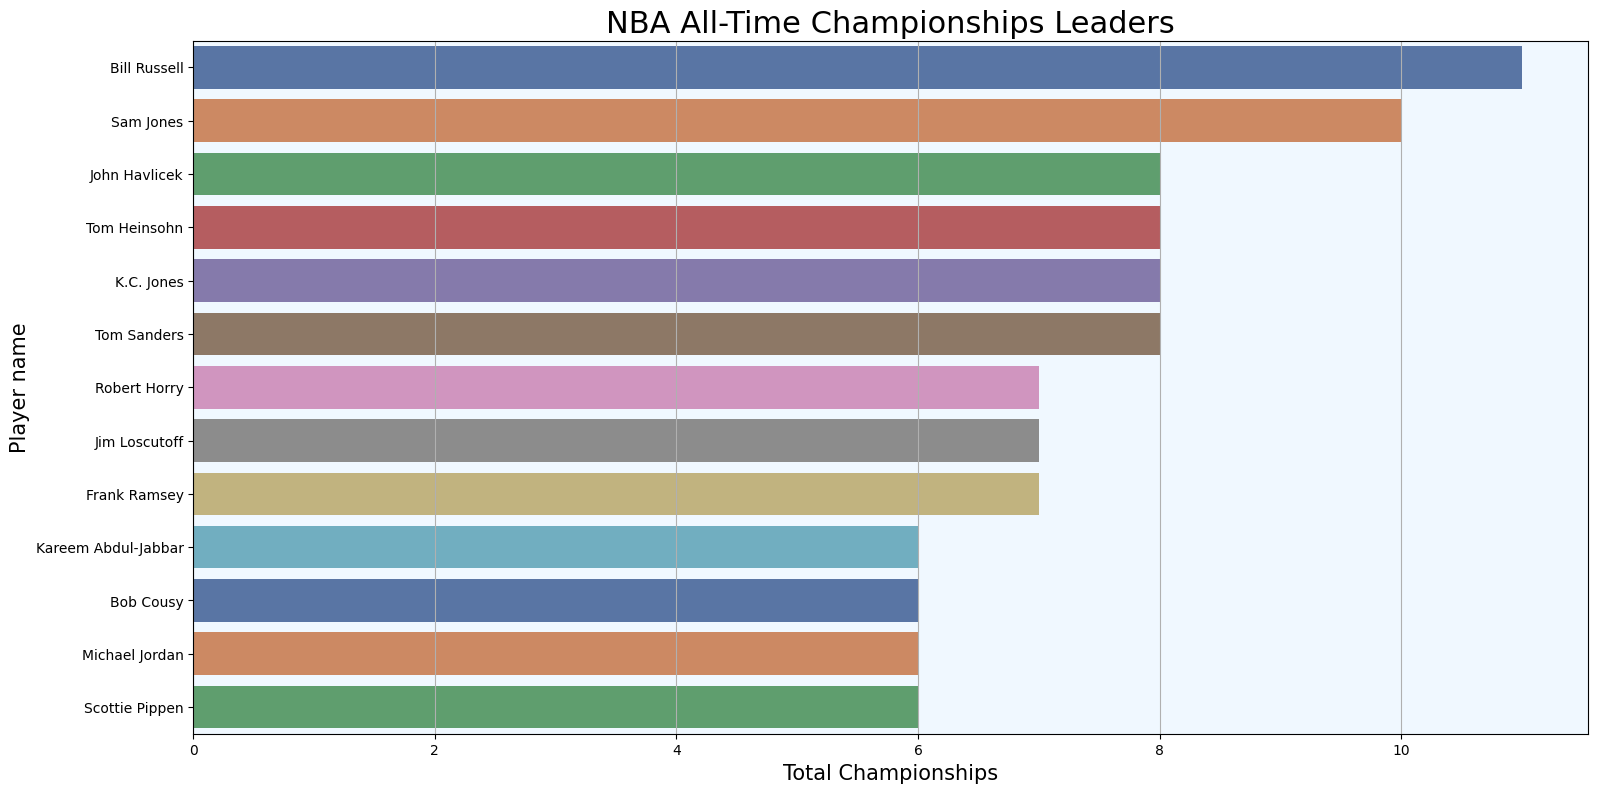

In [39]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=championships_table.Player[:13], x=championships_table.championships[:13], palette='deep')
plt.title('NBA All-Time Championships Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total Championships',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.show()

### Career data
Next we calculate for each player his career totals (points, assists, rebounds etc.) by adding up his season totals. If a statistic was not recorded in any of the seasons of a player (e.g. steals before 1973-74), his career total stays empty instead of 0:

In [40]:
attributes_total_list = ['MP','FG','FGA','3P','3PA','TRB','ORB','AST','STL','BLK','TOV','PTS','FT','FTA']
career_totals = totals_no_duplicates.groupby('player_id')[attributes_total_list].sum(min_count=1).add_prefix('total_')
career_data = totals_no_duplicates.groupby('player_id').agg({'Player':'last','G':'sum'}).join(career_totals)

We also add the number of mvp awards of every player and the number of games he played in the seasons where 3-pointers, steals, blocks and turnovers were recorded, which we will need for the per-game statistics later on:

In [41]:
career_data = career_data.join(mvpawards_per_player.set_index('player_id')['MVP'])
career_data['MVP'] = career_data['MVP'].fillna(0) #players that are not in the per-game data (less than 1 minute per game)

tracked_stats = ['3P','STL','BLK','TOV']
games_tracked = totals_no_duplicates[tracked_stats].notna().mul(totals_no_duplicates.G, axis=0) #games of the seasons where each statistic was recorded
career_data = career_data.join(games_tracked.groupby(totals_no_duplicates.player_id).sum().add_prefix('G_tracked_'))
career_data = career_data.reset_index()

### Minutes played
Next we will showcase the players with the most minutes played per game in a single season.

In [42]:
data_no_duplicates.sort_values(by=['MP'], ascending=False)[['Player','Season','Tm','MP']].head(10).reset_index(drop=True)

,Player,Season,Tm,MP
0,Wilt Chamberlain,1961-62,PHW,48.5
1,Wilt Chamberlain,1960-61,PHW,47.8
2,Wilt Chamberlain,1962-63,SFW,47.6
3,Wilt Chamberlain,1965-66,PHI,47.3
4,Wilt Chamberlain,1967-68,PHI,46.8
5,Wilt Chamberlain,1959-60,PHW,46.4
6,Wilt Chamberlain,1963-64,SFW,46.1
7,Oscar Robertson,1965-66,CIN,46.0
8,Tiny Archibald,1972-73,KCO,46.0
9,Oscar Robertson,1964-65,CIN,45.6


Sorting the data based on the total number of minutes played:

In [43]:
career_data = career_data.sort_values(by=['total_MP'], ascending=False)

Lastly, we are going to visualize the results:

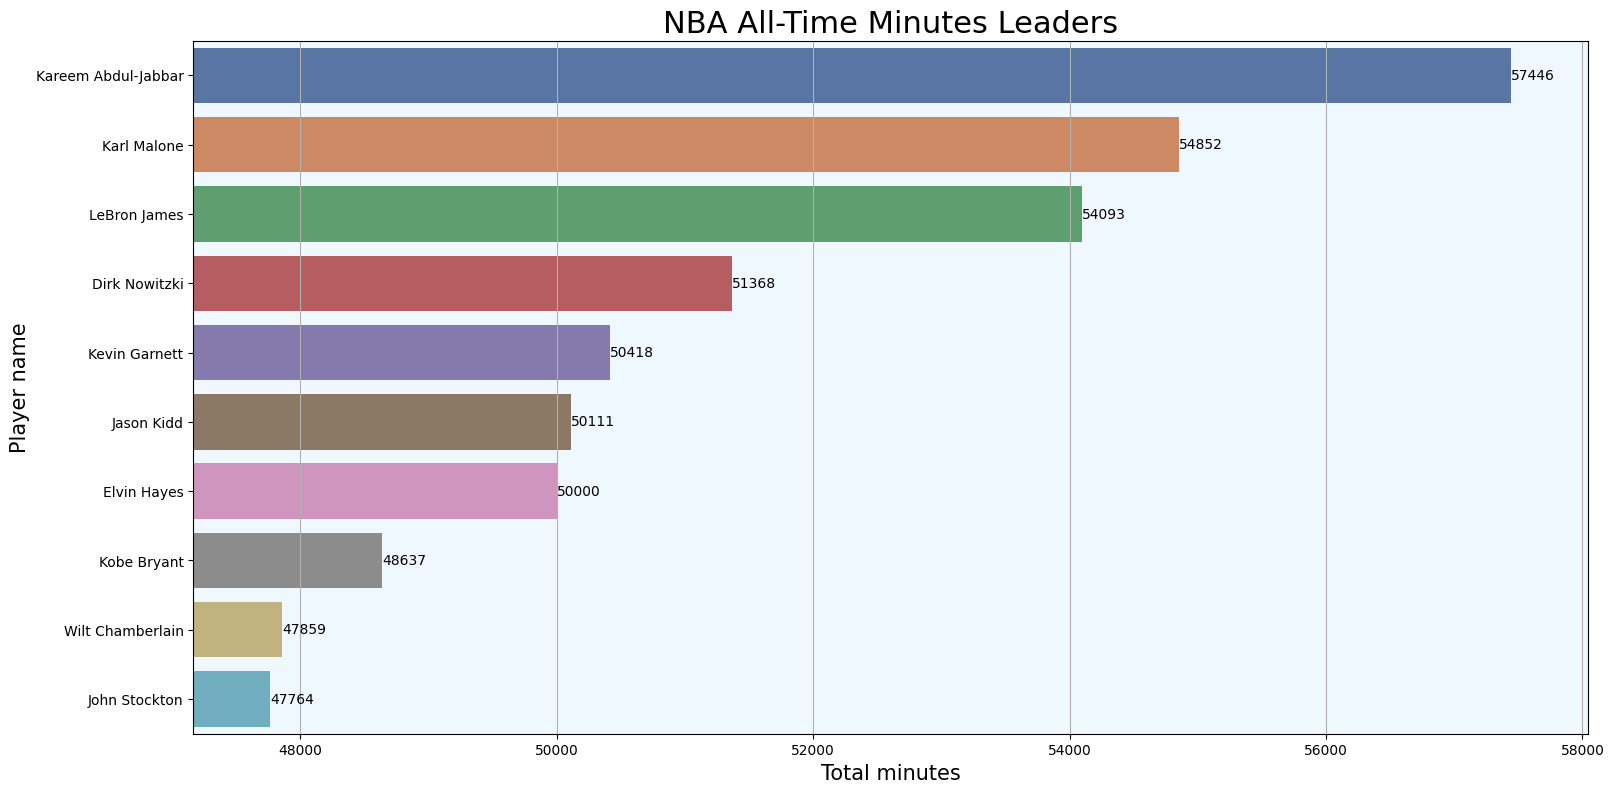

In [44]:
fig, ax = plt.subplots(figsize=fig_dims)
ax = sns.barplot(y=career_data.Player[:10], x=career_data.total_MP[:10].round(), palette='deep')
plt.title('NBA All-Time Minutes Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total minutes',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.xlim(career_data.iloc[9,career_data.columns.get_loc('total_MP')] - 600,
        career_data.iloc[0,career_data.columns.get_loc('total_MP')]+ 600)
#setting x axis ranges close to the top 10
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Field Goal percentage
Next we will evaluate the field goal percentage. Firstly, we find the players with the highest field goal percentage in a single season. For that we set a requirement of minimum 40 games played for that player in that specific season: 

In [45]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(by='FG%', ascending=False)[['Player','Season','Tm','FG%']].head(10)\
                                            .reset_index(drop=True)

,Player,Season,Tm,FG%
0,Jericho Sims,2022-23,NYK,0.776
1,DeAndre Jordan,2020-21,BRK,0.763
2,Mitchell Robinson,2021-22,NYK,0.761
3,Mitchell Robinson,2019-20,NYK,0.742
4,Ryan Hollins,2013-14,LAC,0.736
5,Robert Williams,2021-22,BOS,0.736
6,Daniel Gafford,2022-23,WAS,0.732
7,Dwight Powell,2022-23,DAL,0.732
8,Dwight Howard,2019-20,LAL,0.729
9,Wilt Chamberlain,1972-73,LAL,0.727


Now we continue by finding the players with the highest career field goal percentages. Players that took only a few shots can have extremely high percentages, so we use the same minimum as the career leaderboard of basketball-reference: at least 2,000 field goals made:

In [46]:
career_data['FG%'] = career_data.total_FG / career_data.total_FGA
career_data_FG = career_data.loc[career_data.total_FG >= 2000].sort_values(by='FG%', ascending=False)

Now we can visualize the results:

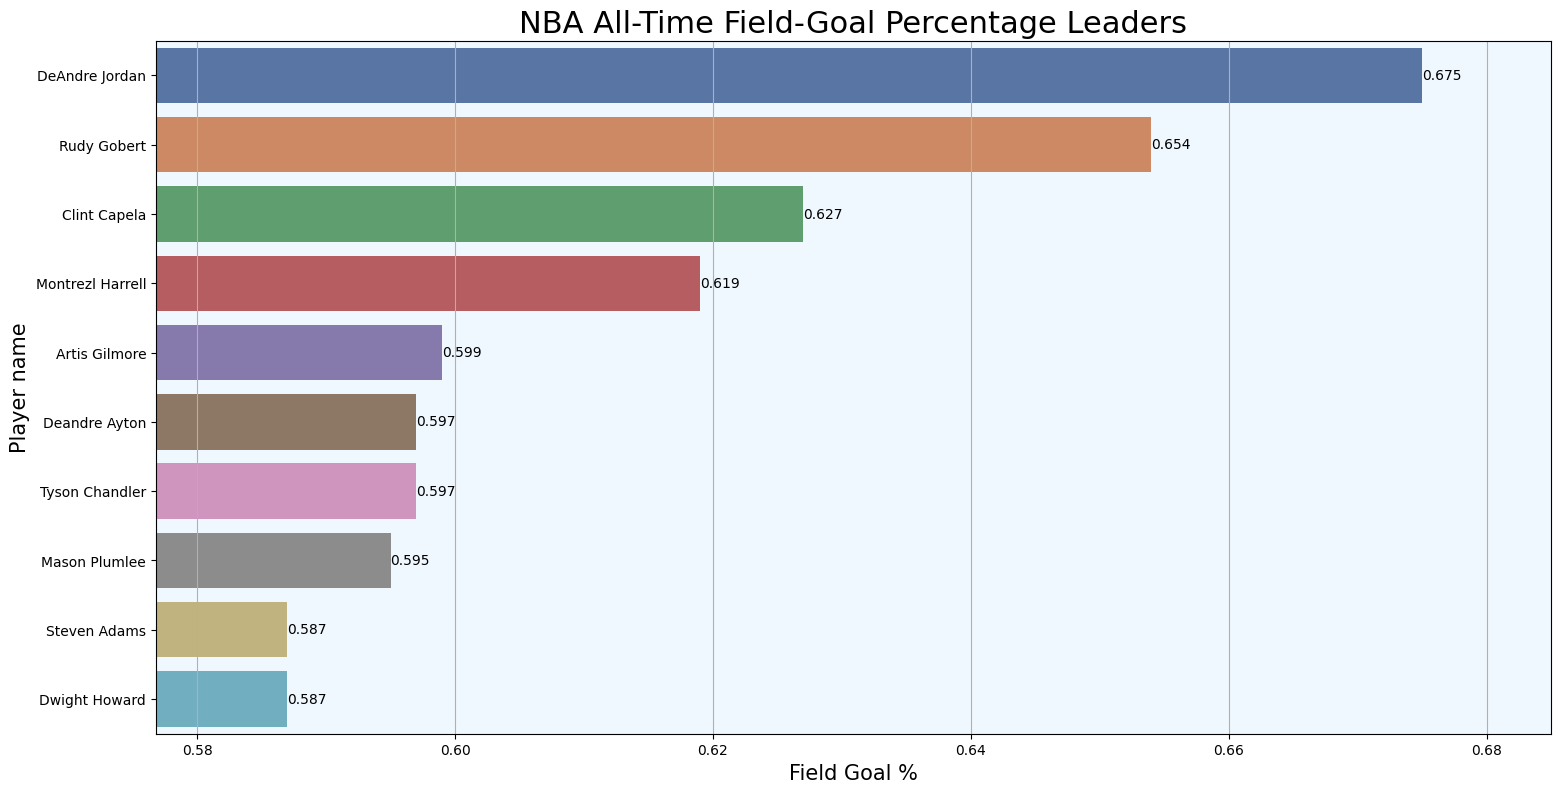

In [47]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data_FG.Player[:10], x=career_data_FG['FG%'][:10].round(3), palette='deep')
plt.title('NBA All-Time Field-Goal Percentage Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Field Goal %',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
ax.grid(axis='x') #add grid
plt.xlim(career_data_FG.iloc[9,career_data_FG.columns.get_loc('FG%')] - 0.01,
        career_data_FG.iloc[0,career_data_FG.columns.get_loc('FG%')]+ 0.01)
#setting x axis ranges close to the percentage
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### 3 Point
Now we will focus on the 3 point statistics. Firstly show the players with the highest 3 point percentage for a single season, minimum 40 games played and more than one 3-point attempt on average per game:

In [48]:
data_no_duplicates.loc[(data_no_duplicates.G >= 40) & (data_no_duplicates['3PA'] > 1)].sort_values(by='3P%', ascending=False)\
                                                    [['Player','Season','Tm','3P%']].head(10).reset_index(drop=True)

,Player,Season,Tm,3P%
0,Tony Snell,2020-21,ATL,0.569
1,Pau Gasol,2016-17,SAS,0.538
2,Kyle Korver,2009-10,UTA,0.536
3,Steve Kerr,1994-95,CHI,0.524
4,Jon Sundvold,1988-89,MIA,0.522
5,Tim Legler,1995-96,WSB,0.522
6,Steve Kerr,1995-96,CHI,0.515
7,Jason Kapono,2006-07,MIA,0.514
8,Detlef Schrempf,1994-95,SEA,0.514
9,Luke Babbitt,2014-15,NOP,0.513


Now we calculate the career 3-point percentages and sort the values, only keeping the players with at least 250 3-pointers made (the minimum of basketball-reference):

In [49]:
career_data['3P%'] = career_data.total_3P / career_data.total_3PA
career_data_3P = career_data.loc[career_data.total_3P >= 250].sort_values(by='3P%', ascending=False)

Now we visualize the results

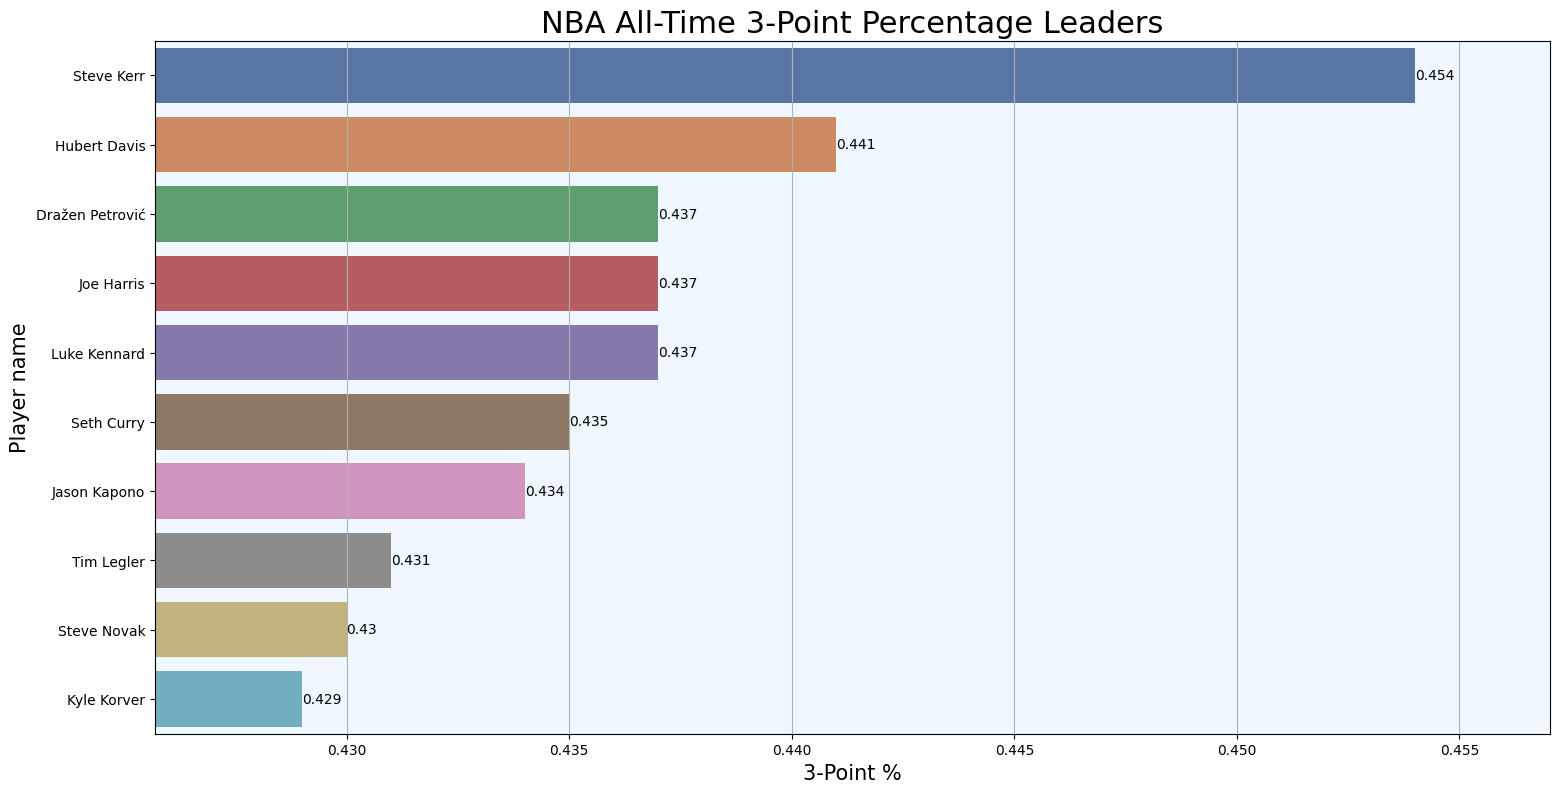

In [50]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data_3P.Player[:10], x=career_data_3P['3P%'][:10].round(3), palette='deep')
plt.title('NBA All-Time 3-Point Percentage Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('3-Point %',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data_3P.iloc[9, career_data_3P.columns.get_loc('3P%')] - 0.003,
         career_data_3P.iloc[0, career_data_3P.columns.get_loc('3P%')]+ 0.003)
#setting x axis ranges to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

Now we focus on the players with the most 3 pointers scored

In [51]:
career_data_3P = career_data_3P.sort_values(by='total_3P', ascending=False)

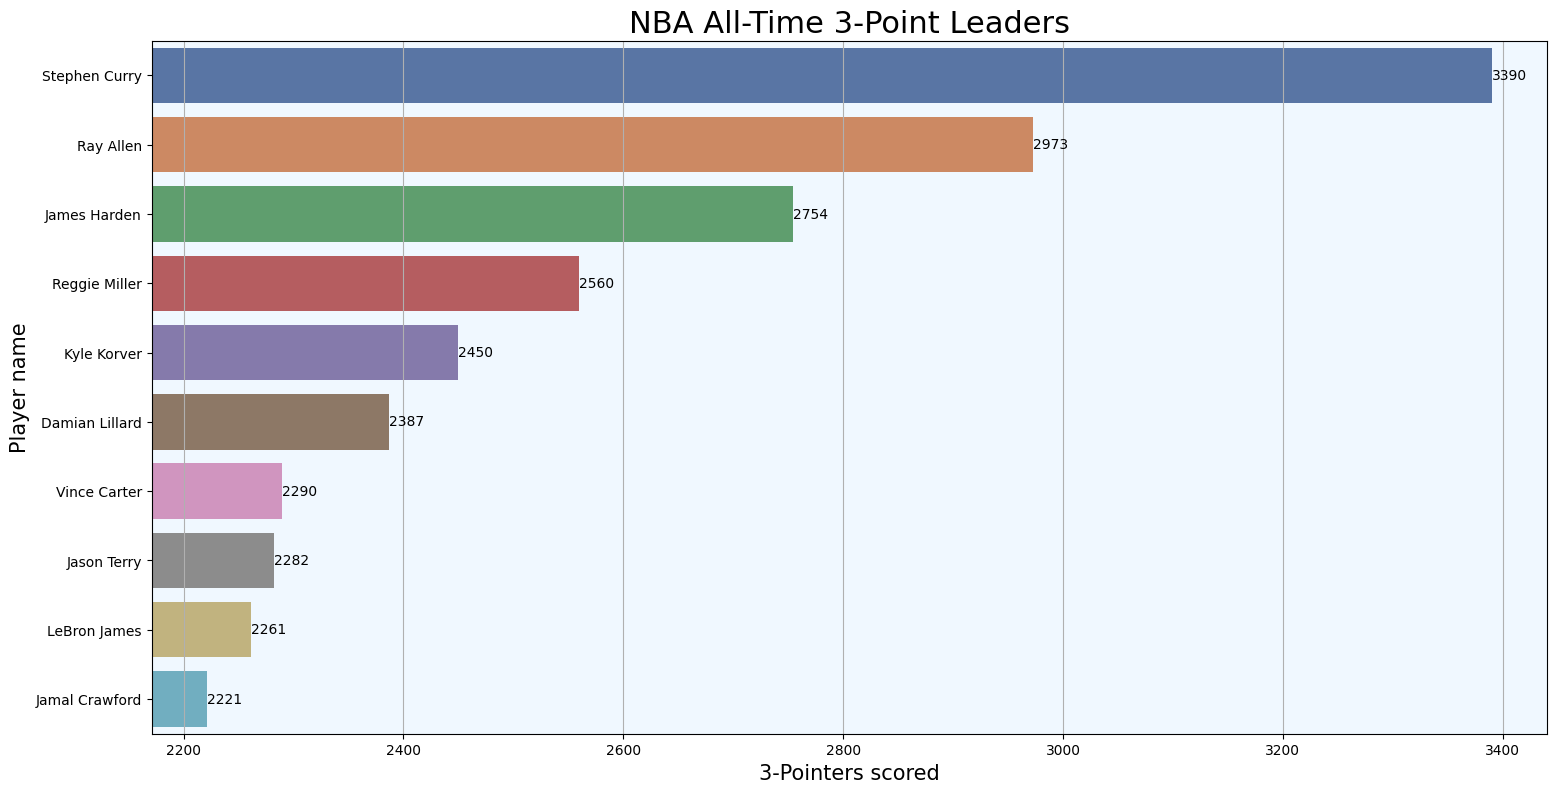

In [52]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data_3P.Player[:10], x=career_data_3P['total_3P'][:10].round(), palette='deep')
plt.title('NBA All-Time 3-Point Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('3-Pointers scored',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data_3P.iloc[9, career_data_3P.columns.get_loc('total_3P')] - 50,
         career_data_3P.iloc[0, career_data_3P.columns.get_loc('total_3P')]+ 50)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Free throws
Next we will check the free throws. Firstly, the players with the most average free throws scored per game in a single season, minimum 40 games played per season.

In [53]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(by='FT', ascending=False)[['Player','Tm','Season','FT']]\
                                                            .head(10).reset_index(drop=True)

,Player,Tm,Season,FT
0,Jerry West,LAL,1965-66,10.6
1,Wilt Chamberlain,PHW,1961-62,10.4
2,Adrian Dantley,UTA,1983-84,10.3
3,James Harden,HOU,2019-20,10.2
4,Michael Jordan,CHI,1986-87,10.2
5,Oscar Robertson,CIN,1963-64,10.1
6,Joel Embiid,PHI,2022-23,10.0
7,Elgin Baylor,LAL,1961-62,9.9
8,Oscar Robertson,CIN,1965-66,9.8
9,Shai Gilgeous-Alexander,OKC,2022-23,9.8


Next we will see the players with the best free throw percentages for a single season, minimum 40 games played and more than 1 free throw attempt per game

In [54]:
data_no_duplicates.loc[(data_no_duplicates.G >= 40) & (data_no_duplicates.FTA > 1)].sort_values(by='FT%', ascending=False)\
                                                    [['Player','Tm','Season','FT%']].head(10).reset_index(drop=True)

,Player,Tm,Season,FT%
0,José Calderón,TOR,2008-09,0.981
1,Calvin Murphy,HOU,1980-81,0.958
2,Mahmoud Abdul-Rauf,DEN,1993-94,0.956
3,Ray Allen,BOS,2008-09,0.952
4,Jeff Hornacek,UTA,1999-00,0.950
5,Mark Price,CLE,1992-93,0.948
6,Rick Barry,HOU,1978-79,0.947
7,Mark Price,CLE,1991-92,0.947
8,Ernie DiGregorio,BUF,1976-77,0.945
9,JJ Redick,TOT,2020-21,0.942


Now the career free throw percentage is calculated. Only the players with at least 1,200 free throws made are considered (the minimum of basketball-reference):

In [55]:
career_data['FT%'] = career_data.total_FT / career_data.total_FTA
career_data_FT = career_data.loc[career_data.total_FT >= 1200].sort_values(by='FT%', ascending=False)

Visualizing the results

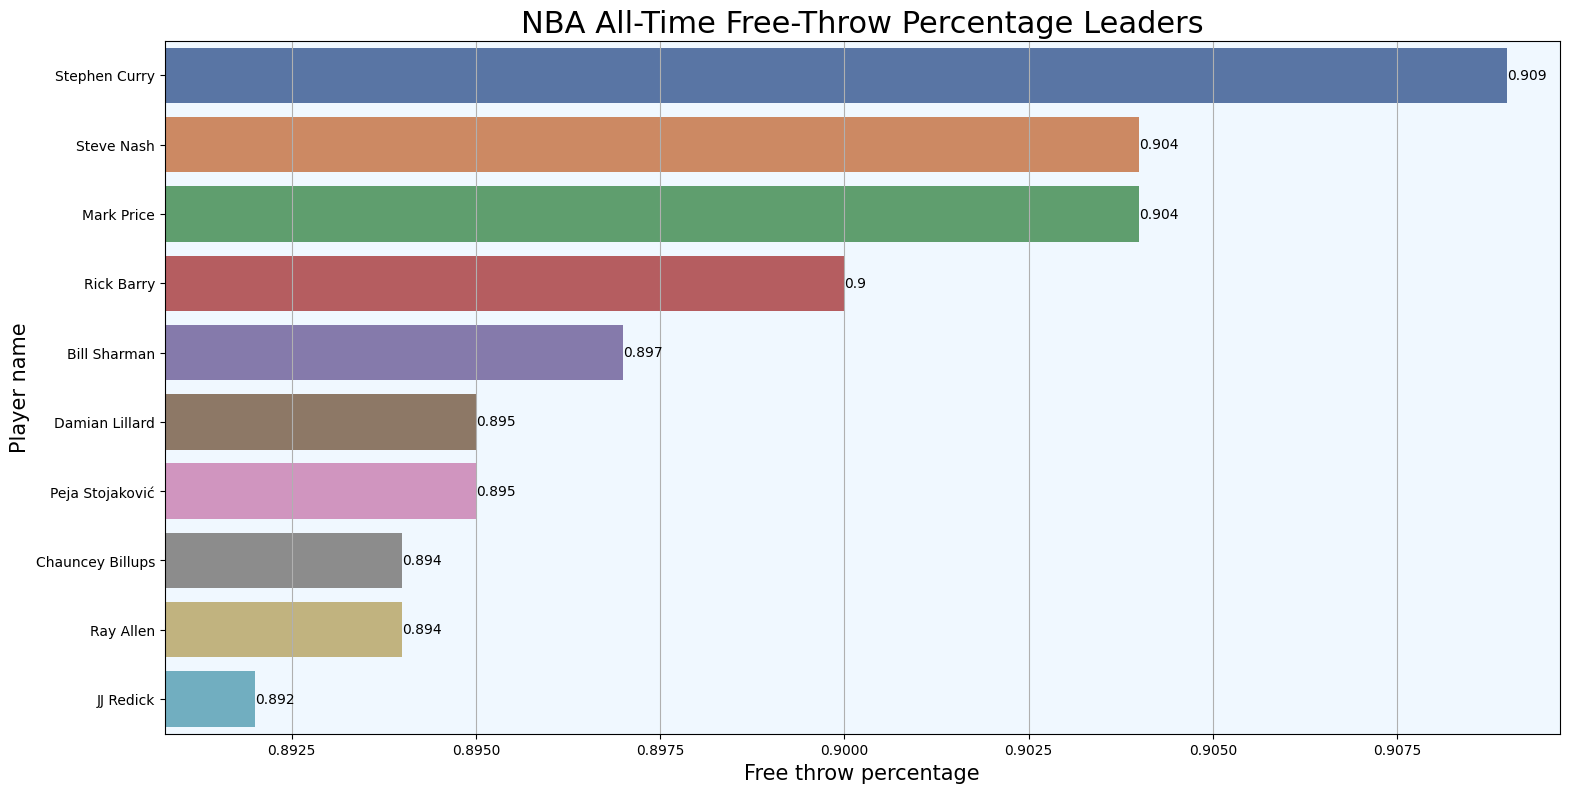

In [56]:
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data_FT.Player[:10], x=career_data_FT['FT%'][:10].round(3), palette='deep')
plt.title('NBA All-Time Free-Throw Percentage Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Free throw percentage',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data_FT.iloc[9, career_data_FT.columns.get_loc('FT%')] - 0.001,
         career_data_FT.iloc[0, career_data_FT.columns.get_loc('FT%')]+ 0.001)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Rebounds
Now it's time for the best rebounders. We will check the best rebounding seasons, minimum 40 games played:

In [57]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(by='TRB', ascending=False)[['Player','Tm','Season','TRB']]\
                                                    .head(10).reset_index(drop=True)

,Player,Tm,Season,TRB
0,Wilt Chamberlain,PHW,1960-61,27.2
1,Wilt Chamberlain,PHW,1959-60,27.0
2,Wilt Chamberlain,PHW,1961-62,25.7
3,Bill Russell,BOS,1963-64,24.7
4,Wilt Chamberlain,PHI,1965-66,24.6
5,Wilt Chamberlain,SFW,1962-63,24.3
6,Wilt Chamberlain,PHI,1966-67,24.2
7,Bill Russell,BOS,1964-65,24.1
8,Bill Russell,BOS,1959-60,24.0
9,Bill Russell,BOS,1960-61,23.9


Visualizing the players with the most career rebounds:

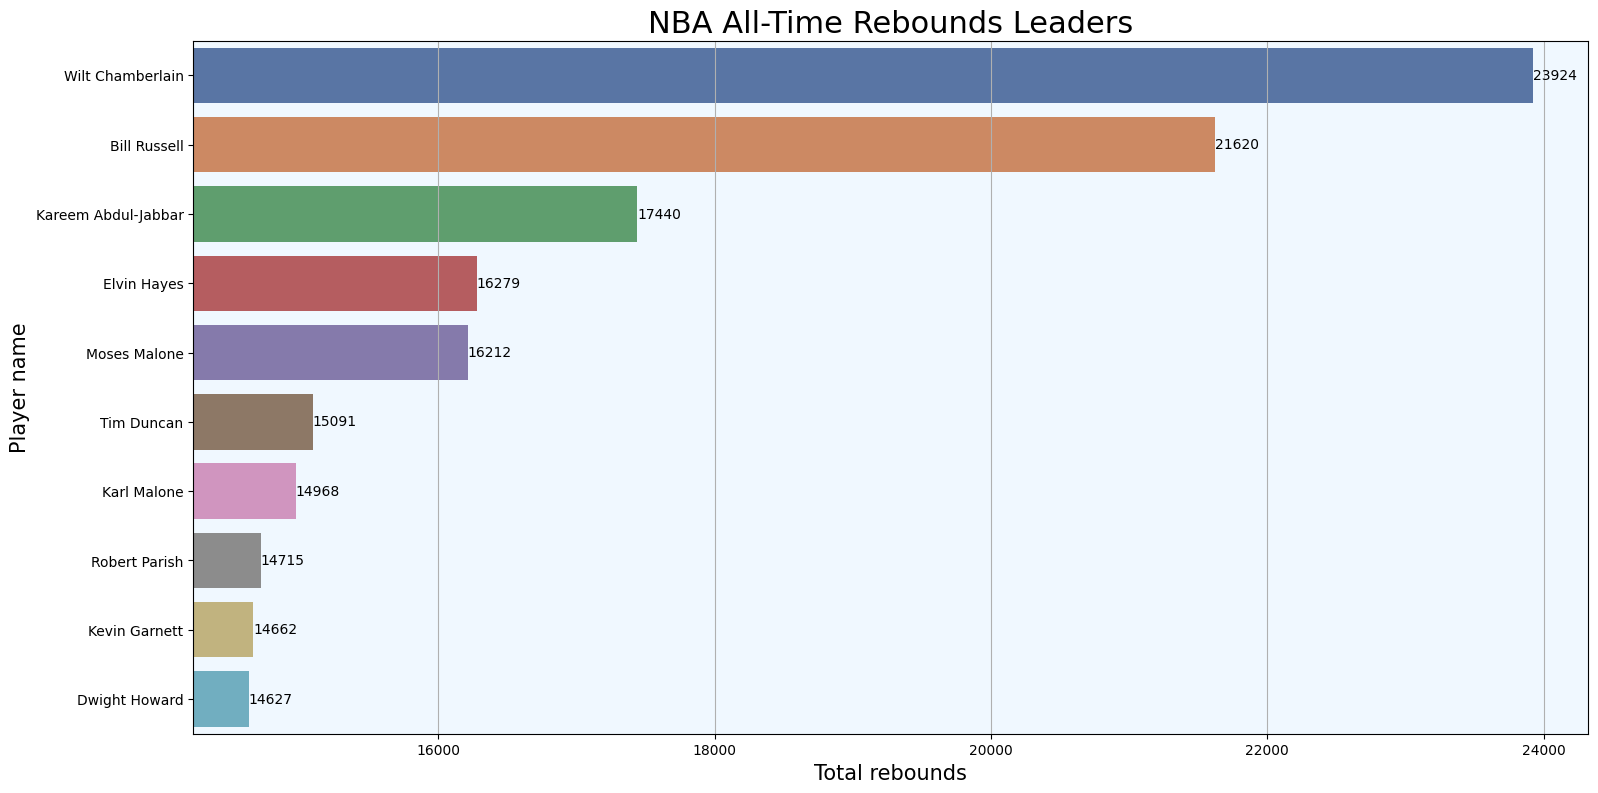

In [58]:
career_data = career_data.sort_values(by='total_TRB', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_TRB'][:10].round(), palette='deep')
plt.title('NBA All-Time Rebounds Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total rebounds',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_TRB')] - 400,
         career_data.iloc[0, career_data.columns.get_loc('total_TRB')]+ 400)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

Now offensive rebounds, which are recorded since the 1973-74 season:

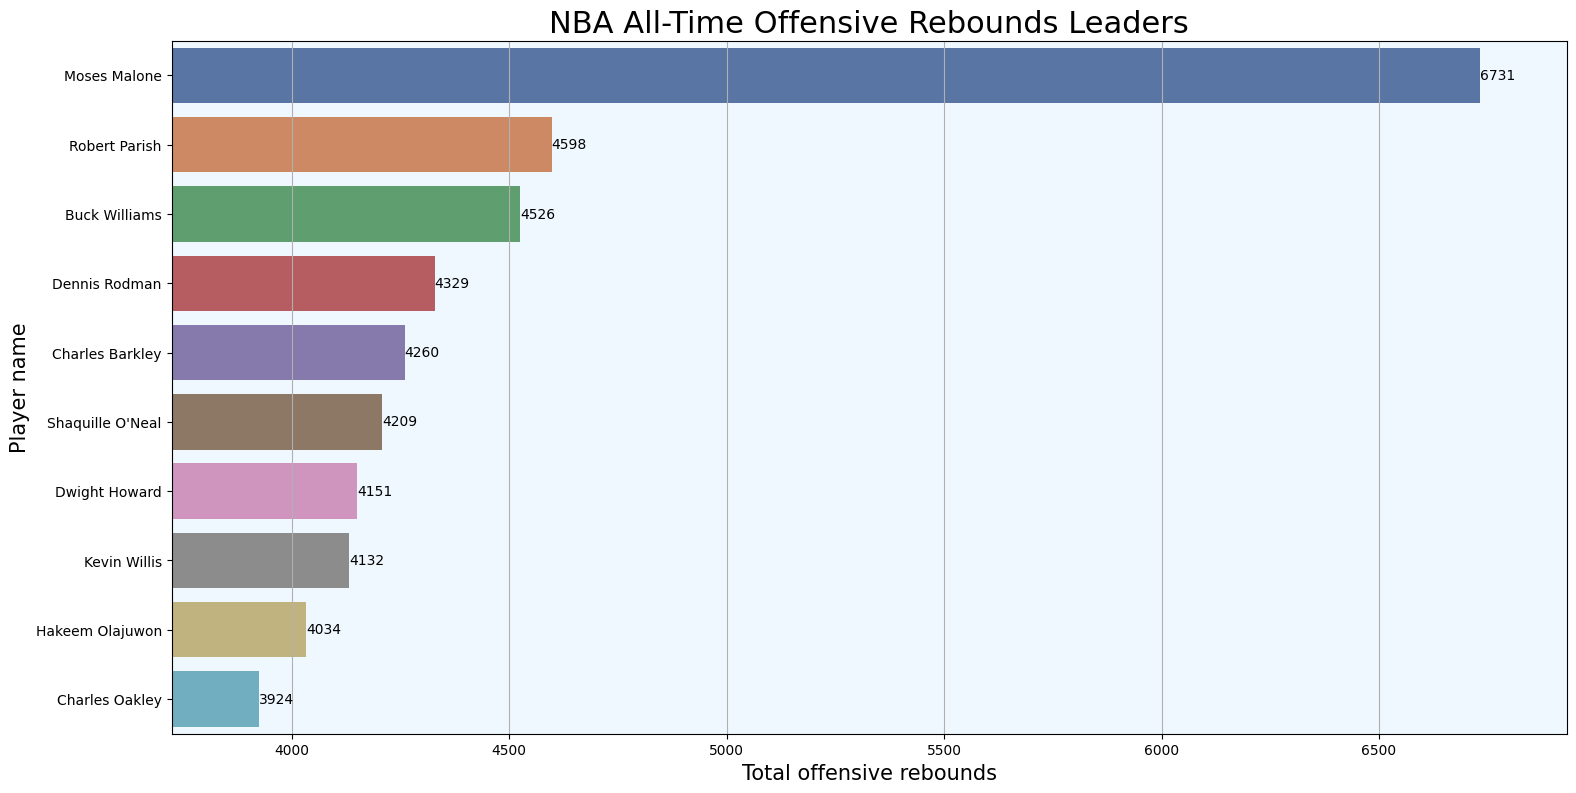

In [59]:
career_data = career_data.sort_values(by='total_ORB', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_ORB'][:10].round(), palette='deep')
plt.title('NBA All-Time Offensive Rebounds Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total offensive rebounds',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_ORB')] - 200,
         career_data.iloc[0, career_data.columns.get_loc('total_ORB')]+ 200)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Assists
Now it is time to analyze the assists. Firstly, the players with the highest assist per game in a single season, minimum 40 games. In case of a tie, the player that has played in more games outdoes his competitor:

In [60]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(['AST','G'], ascending=False)[['Player','Tm','Season','AST']]\
                                                                        .head(10).reset_index(drop=True)

,Player,Tm,Season,AST
0,John Stockton,UTA,1989-90,14.5
1,John Stockton,UTA,1990-91,14.2
2,Isiah Thomas,DET,1984-85,13.9
3,John Stockton,UTA,1987-88,13.8
4,John Stockton,UTA,1991-92,13.7
5,John Stockton,UTA,1988-89,13.6
6,Kevin Porter,DET,1978-79,13.4
7,Magic Johnson,LAL,1983-84,13.1
8,Magic Johnson,LAL,1988-89,12.8
9,John Stockton,UTA,1993-94,12.6


Visualizing the career assists:

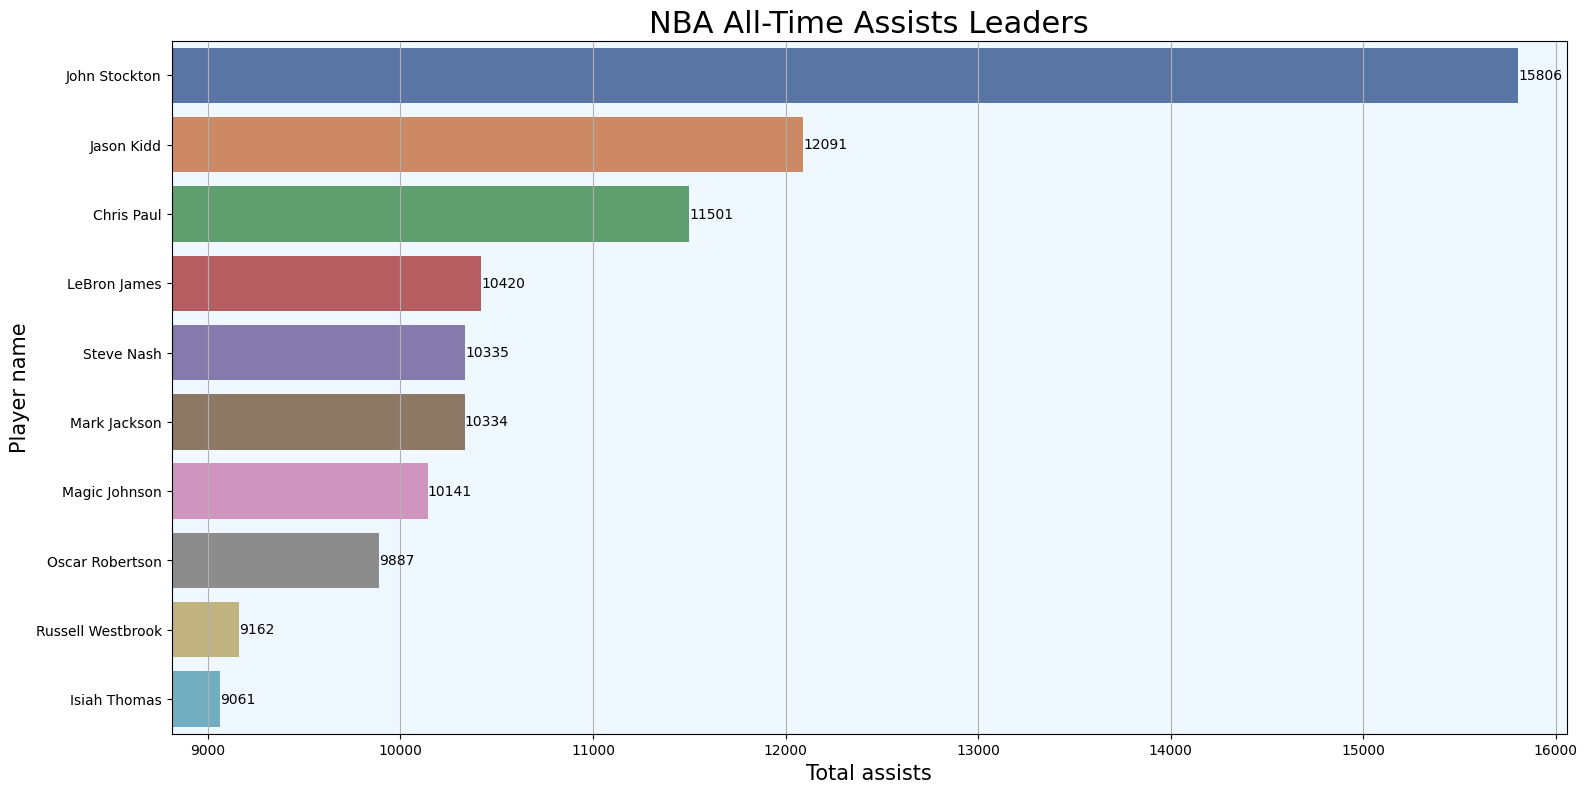

In [61]:
career_data = career_data.sort_values(by='total_AST', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_AST'][:10].round(), palette='deep')
plt.title('NBA All-Time Assists Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total assists',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_AST')] - 250,
         career_data.iloc[0, career_data.columns.get_loc('total_AST')]+ 250)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Steals
Next up steals, which are recorded since the 1973-74 season. Firstly, the highest steals per game in a single season, with a minimum of 40 games played:

In [62]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(['STL','G'], ascending=False)[['Player','Tm','Season','STL']]\
                                                                        .head(10).reset_index(drop=True)

,Player,Tm,Season,STL
0,Alvin Robertson,SAS,1985-86,3.7
1,Don Buse,IND,1976-77,3.5
2,Slick Watts,SEA,1975-76,3.2
3,Michael Ray Richardson,NYK,1979-80,3.2
4,Michael Jordan,CHI,1987-88,3.2
5,John Stockton,UTA,1988-89,3.2
6,Alvin Robertson,SAS,1986-87,3.2
7,Michael Ray Richardson,NJN,1984-85,3.0
8,Alvin Robertson,SAS,1987-88,3.0
9,John Stockton,UTA,1987-88,3.0


Now the results:

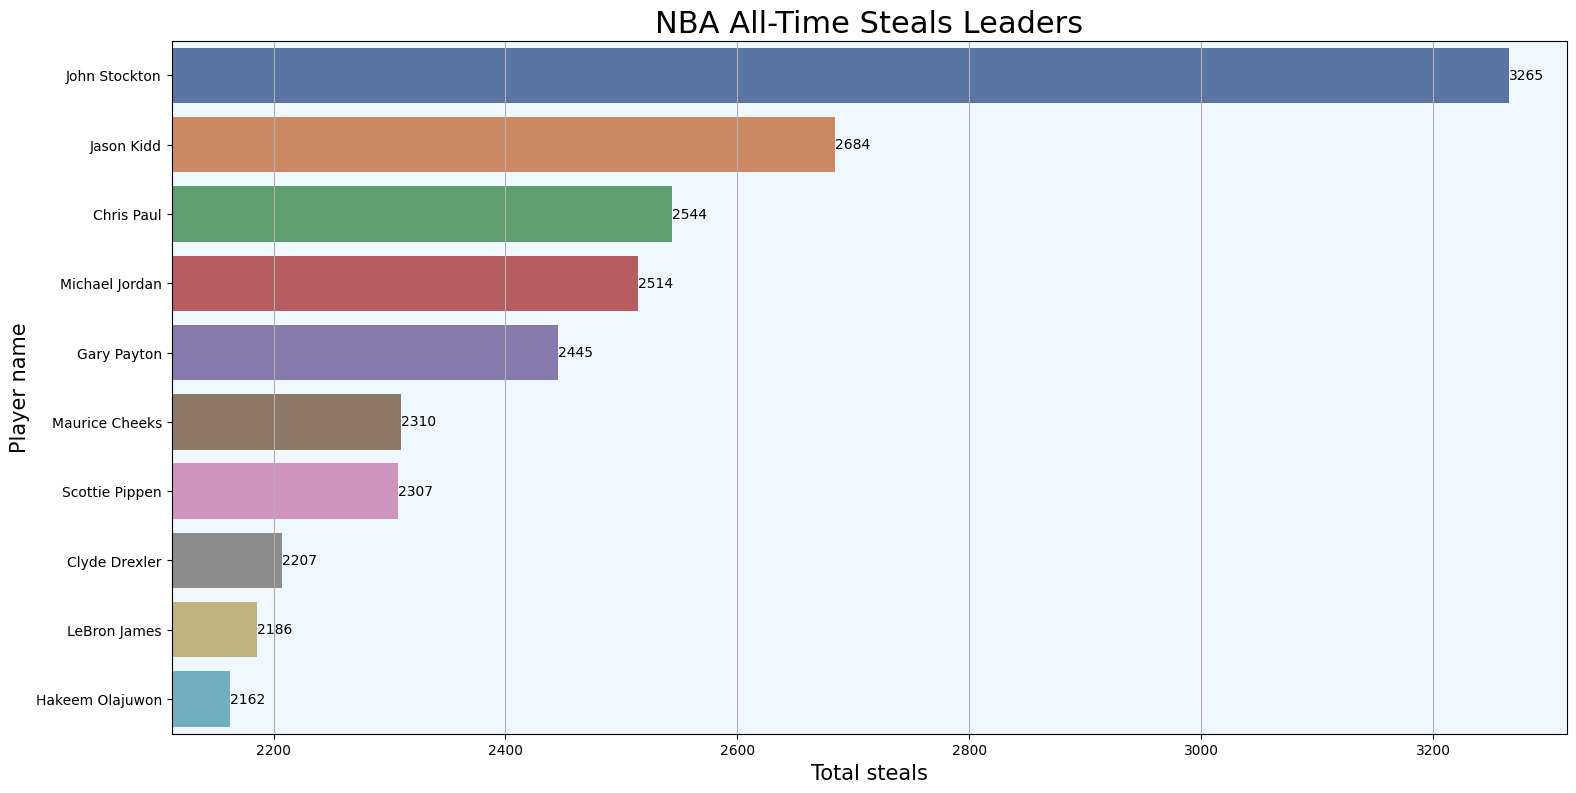

In [63]:
career_data = career_data.sort_values(by='total_STL', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_STL'][:10].round(), palette='deep')
plt.title('NBA All-Time Steals Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total steals',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_STL')] - 50,
         career_data.iloc[0, career_data.columns.get_loc('total_STL')]+ 50)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Blocks
Next up blocks, which are also recorded since the 1973-74 season. Firstly, the highest blocks per game in a single season, with a minimum of 40 games played:

In [64]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(['BLK','G'], ascending=False)[['Player','Tm','Season','BLK']]\
                                                                            .head(10).reset_index(drop=True)

,Player,Tm,Season,BLK
0,Mark Eaton,UTA,1984-85,5.6
1,Manute Bol,WSB,1985-86,5.0
2,Elmore Smith,LAL,1973-74,4.9
3,Hakeem Olajuwon,HOU,1989-90,4.6
4,Mark Eaton,UTA,1985-86,4.6
5,Dikembe Mutombo,DEN,1995-96,4.5
6,David Robinson,SAS,1991-92,4.5
7,Mark Eaton,UTA,1983-84,4.3
8,Tree Rollins,ATL,1982-83,4.3
9,Manute Bol,GSW,1988-89,4.3


Let's check the top 10 blockers:

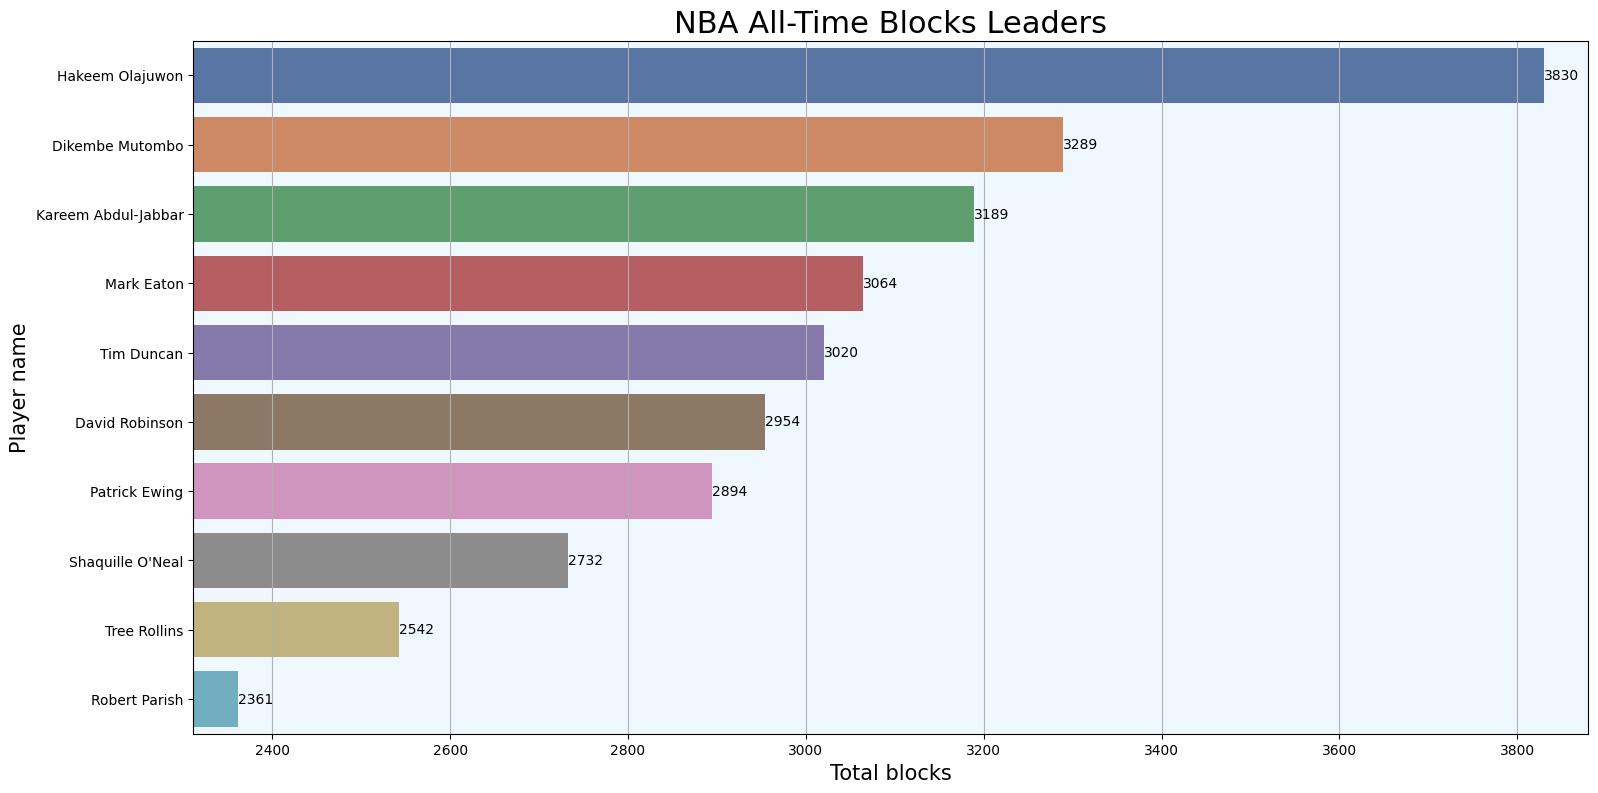

In [65]:
career_data = career_data.sort_values(by='total_BLK', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_BLK'][:10].round(), palette='deep')
plt.title('NBA All-Time Blocks Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total blocks',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_BLK')] - 50,
         career_data.iloc[0, career_data.columns.get_loc('total_BLK')]+ 50)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Points
Next up points. Firstly, the highest points per game in a single season, with a minimum of 40 games played:

In [66]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(['PTS','G'], ascending=False)[['Player','Tm','Season','PTS','G']]\
                                                                    .head(10).reset_index(drop=True)

,Player,Tm,Season,PTS,G
0,Wilt Chamberlain,PHW,1961-62,50.4,80
1,Wilt Chamberlain,SFW,1962-63,44.8,80
2,Wilt Chamberlain,PHW,1960-61,38.4,79
3,Elgin Baylor,LAL,1961-62,38.3,48
4,Wilt Chamberlain,PHW,1959-60,37.6,72
5,Michael Jordan,CHI,1986-87,37.1,82
6,Wilt Chamberlain,SFW,1963-64,36.9,80
7,James Harden,HOU,2018-19,36.1,78
8,Rick Barry,SFW,1966-67,35.6,78
9,Kobe Bryant,LAL,2005-06,35.4,80


Now let's visualize the top 10 all time scorers:

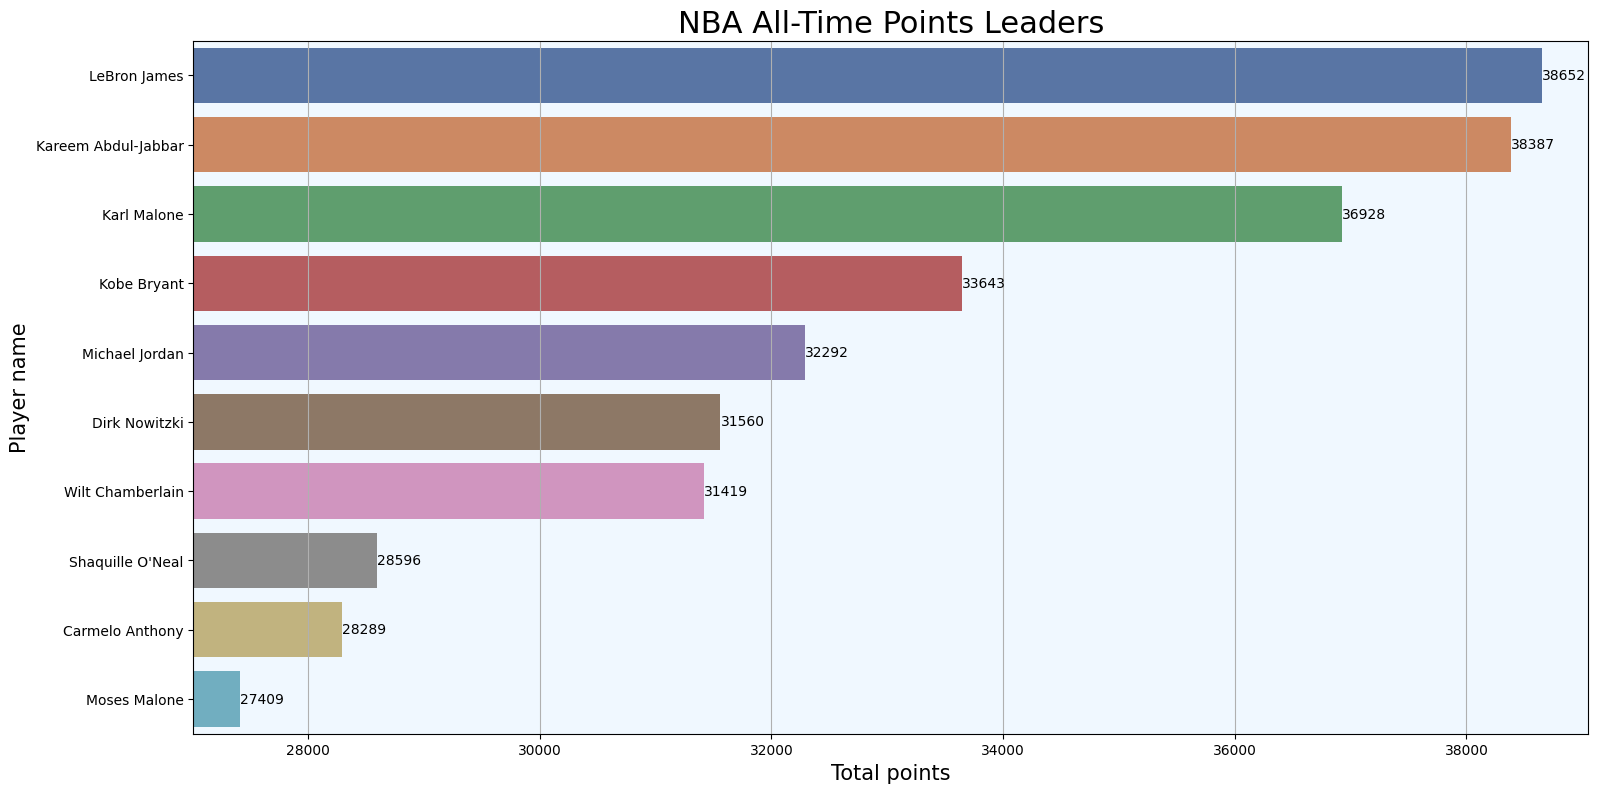

In [67]:
career_data = career_data.sort_values(by='total_PTS', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_PTS'][:10].round(), palette='deep')
plt.title('NBA All-Time Points Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total points',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_PTS')] - 400,
         career_data.iloc[0, career_data.columns.get_loc('total_PTS')]+ 400)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

### Turnovers
Now let's check the players with the highest turnovers per game in a single season (turnovers are recorded since the 1977-78 season), minimum 40 games played

In [68]:
data_no_duplicates.loc[data_no_duplicates.G >= 40].sort_values(['TOV','G'], ascending=False)[['Player','Tm','Season','TOV','G']]\
                                                                            .head(10).reset_index(drop=True)

,Player,Tm,Season,TOV,G
0,James Harden,HOU,2016-17,5.7,81
1,Russell Westbrook,OKC,2016-17,5.4,81
2,James Harden,HOU,2018-19,5.0,78
3,Pete Maravich,NOJ,1977-78,5.0,50
4,DeMarcus Cousins,NOP,2017-18,5.0,48
5,Russell Westbrook,OKC,2017-18,4.8,80
6,Russell Westbrook,WAS,2020-21,4.8,65
7,Trae Young,ATL,2019-20,4.8,60
8,Ray Williams,KCK,1982-83,4.7,72
9,Charles Barkley,PHI,1986-87,4.7,68


Next we will calculate the players with most turnovers in nba history:

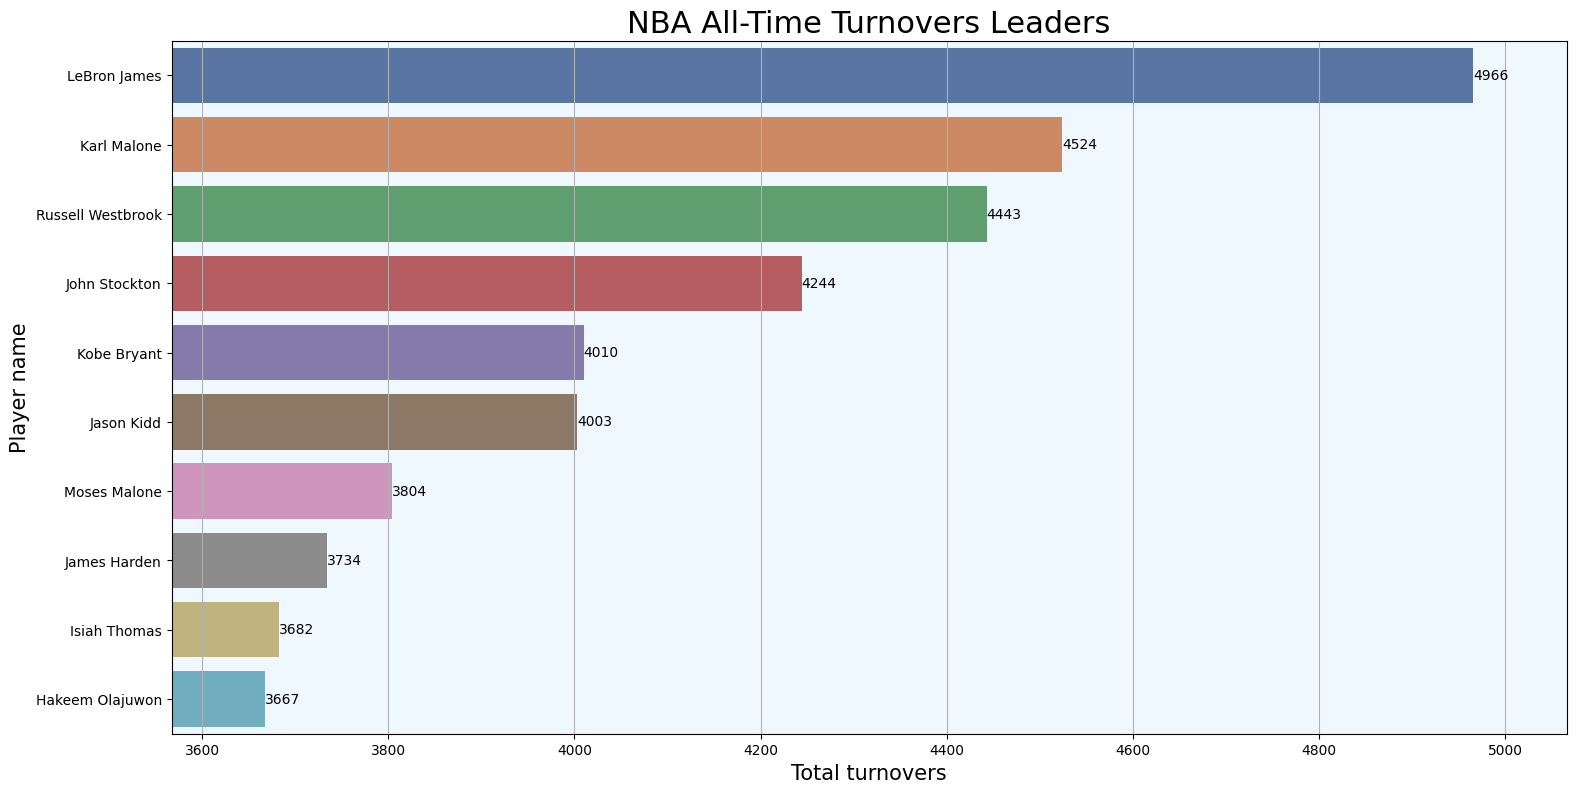

In [69]:
career_data = career_data.sort_values(by='total_TOV', ascending=False) #sorting values
fig, ax = plt.subplots(figsize=fig_dims)
sns.barplot(y=career_data.Player[:10], x=career_data['total_TOV'][:10].round(), palette='deep')
plt.title('NBA All-Time Turnovers Leaders', fontdict ={'size': 22})
plt.ylabel('Player name', fontdict ={'size': 15})
plt.xlabel('Total turnovers',fontdict ={'size': 15})
ax.set_facecolor("aliceblue") #setting background color
plt.xlim(career_data.iloc[9, career_data.columns.get_loc('total_TOV')] - 100,
         career_data.iloc[0, career_data.columns.get_loc('total_TOV')]+ 100)
#setting x axis ranges close to the limits of the top 10
ax.grid(axis='x') #add grid
for i in ax.containers: #printing values next to bars
    ax.bar_label(i)
plt.show()

Because the career numbers are calculated from the season totals, they match the official career totals of basketball-reference (e.g. Karl Malone committed 4,524 turnovers). Keep in mind that the data starts in 1955-56, so the seasons before that are missing for the players whose careers started earlier, and that steals, blocks and turnovers are only counted since they were officially recorded.

### All time great players career stats comparison
We will use a radar plot in order to compare the top players. Firstly, a function script is re-used for the visualizations. Statistics that were not recorded during the career of a player (e.g. turnovers for Bill Russell) are shown as `n/a` and drawn at the centre of the plot, instead of being treated as a real value.

In [70]:
def radar_factory(keys, values, title, axes=None, fontsize=12):

    import math

    if axes is None:
        # Initialise the spider plot.
        plt.figure(figsize=(8, 8))
        ax = plt.subplot(111, polar=True)
    else:
        ax = axes

    # Statistics that were not recorded are drawn at 0 and labeled n/a.
    keys = [key + '\n(n/a)' if np.isnan(value) else key for key, value in zip(keys, values)]
    values = [0 if np.isnan(value) else value for value in values]

    num_categories = len(keys)

    # What will be the angle of each axis in the plot?
    # We divide the plot / number of variables + 1.
    # We add one because we want to do a complete circle.
    angles = np.arange(num_categories + 1)
    angles = angles / num_categories * 2 * np.pi
    angles[-1] = angles[0]

    # We want the first axis to be on top.
    ax.set_theta_offset(np.pi / 2)
    # Theta direction is -1 clockwise,
    # and 1 counterclockwise
    ax.set_theta_direction(-1)

    # Draw one axis per variable and add x labels
    ax.tick_params(labelsize=fontsize)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(keys)

    # Draw y labels
    ax.set_rlabel_position(0)

    values.append(values[0])
    ax.plot(list(angles), values,
            linewidth=1, linestyle='solid')

    ax.fill(angles, values, 'b', alpha=0.1)
    yticks = ax.get_yticks()
    ax.set_yticklabels([])
    ylims = ax.get_ylim()

    max_y = 1 #max value due to MinMaxScaler()
    min_y = 0 #min value due to MinMaxScaler()
    ax.set_ylim(min_y,
               max_y)
    ax.set_title(title,{'fontweight':'bold'})

We only keep players that have played a minimum of 300 games and attempted 600 field goal attempts

In [71]:
career_data_minimum_standards = career_data.loc[(career_data.G >= 300) & (career_data.total_FGA >= 600)].copy()

Now we merge the `championships_table` data into the career dataframe:

In [72]:
career_data_minimum_standards = pd.merge(career_data_minimum_standards,
                                         championships_table[['player_id','championships']],
                                         on=['player_id'], how='left')


Because the championships table only includes players with at least 3 championships, we manually enter the values of the all time greats that won fewer:

In [73]:
career_data_minimum_standards.loc[career_data_minimum_standards.Player == 'Wilt Chamberlain', 'championships'] = 2
career_data_minimum_standards.loc[career_data_minimum_standards.Player == 'Karl Malone', 'championships'] = 0
career_data_minimum_standards.loc[career_data_minimum_standards.Player == 'Hakeem Olajuwon', 'championships'] = 2
career_data_minimum_standards.loc[career_data_minimum_standards.Player == 'John Stockton', 'championships'] = 0
career_data_minimum_standards.loc[career_data_minimum_standards.Player == 'Kevin Durant', 'championships'] = 2

Next, because the career data attributes (points, assists, blocks etc.) vary a lot, we have to set a common scale for all. We will use MinMaxScaler in order to transform all the data in the interval [0,1]. That means that the maximum value for one column (e.g. LeBron James total 38,652 points) will be scaled to 1 and the minimum value of total points will be scaled to 0. In that way all the attributes will have the same scale, which allows the mutual visualization.

Turnovers are the only statistic where a lower number is better, so after scaling we invert them (1 - scaled value): the player with the fewest turnovers gets 1 and the player with the most turnovers gets 0. That is why the axis is labeled `Low TOV`. Keep in mind that the career totals also depend on how long a player played, so the career turnovers are partly a measure of longevity, and for players whose careers started before 1977-78 (e.g. Kareem Abdul-Jabbar) only part of their turnovers is counted.

In [74]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

career_data_columns = ['total_PTS','total_FG','total_3P','total_FT','total_AST','total_TRB','total_STL','total_BLK',
                      'total_TOV', 'MVP', 'championships'] #columns that we are interested

X = scaler.fit_transform(career_data_minimum_standards[career_data_columns]) #scaling data
scaled_career_data = pd.DataFrame(X, index=career_data_minimum_standards.index,
                             columns=career_data_columns) #creating a new dataframe
scaled_career_data['total_TOV'] = 1 - scaled_career_data['total_TOV'] #inverting turnovers, since fewer turnovers is better
scaled_career_data = scaled_career_data.join(career_data_minimum_standards.Player) #adding the player names

Next we can define the column names that we want to showcase on the radar plot and the all time greats that we are interested in:

In [75]:
columns_names_shown = ['PTS','FG','3P','FT','AST','REB','STL','BLK',
                       'Low TOV','MVP', 'CHIPS']
all_time_greats = ['Kobe Bryant','LeBron James','Michael Jordan',"Shaquille O'Neal",
                   'Kareem Abdul-Jabbar','Karl Malone','Bill Russell', 'Wilt Chamberlain',
                   'Magic Johnson','Larry Bird', 'Hakeem Olajuwon',
                    'John Stockton','Tim Duncan','Stephen Curry','Kevin Durant']

Next we use a script to visualize the radar plots of the all time greats, next to each other:

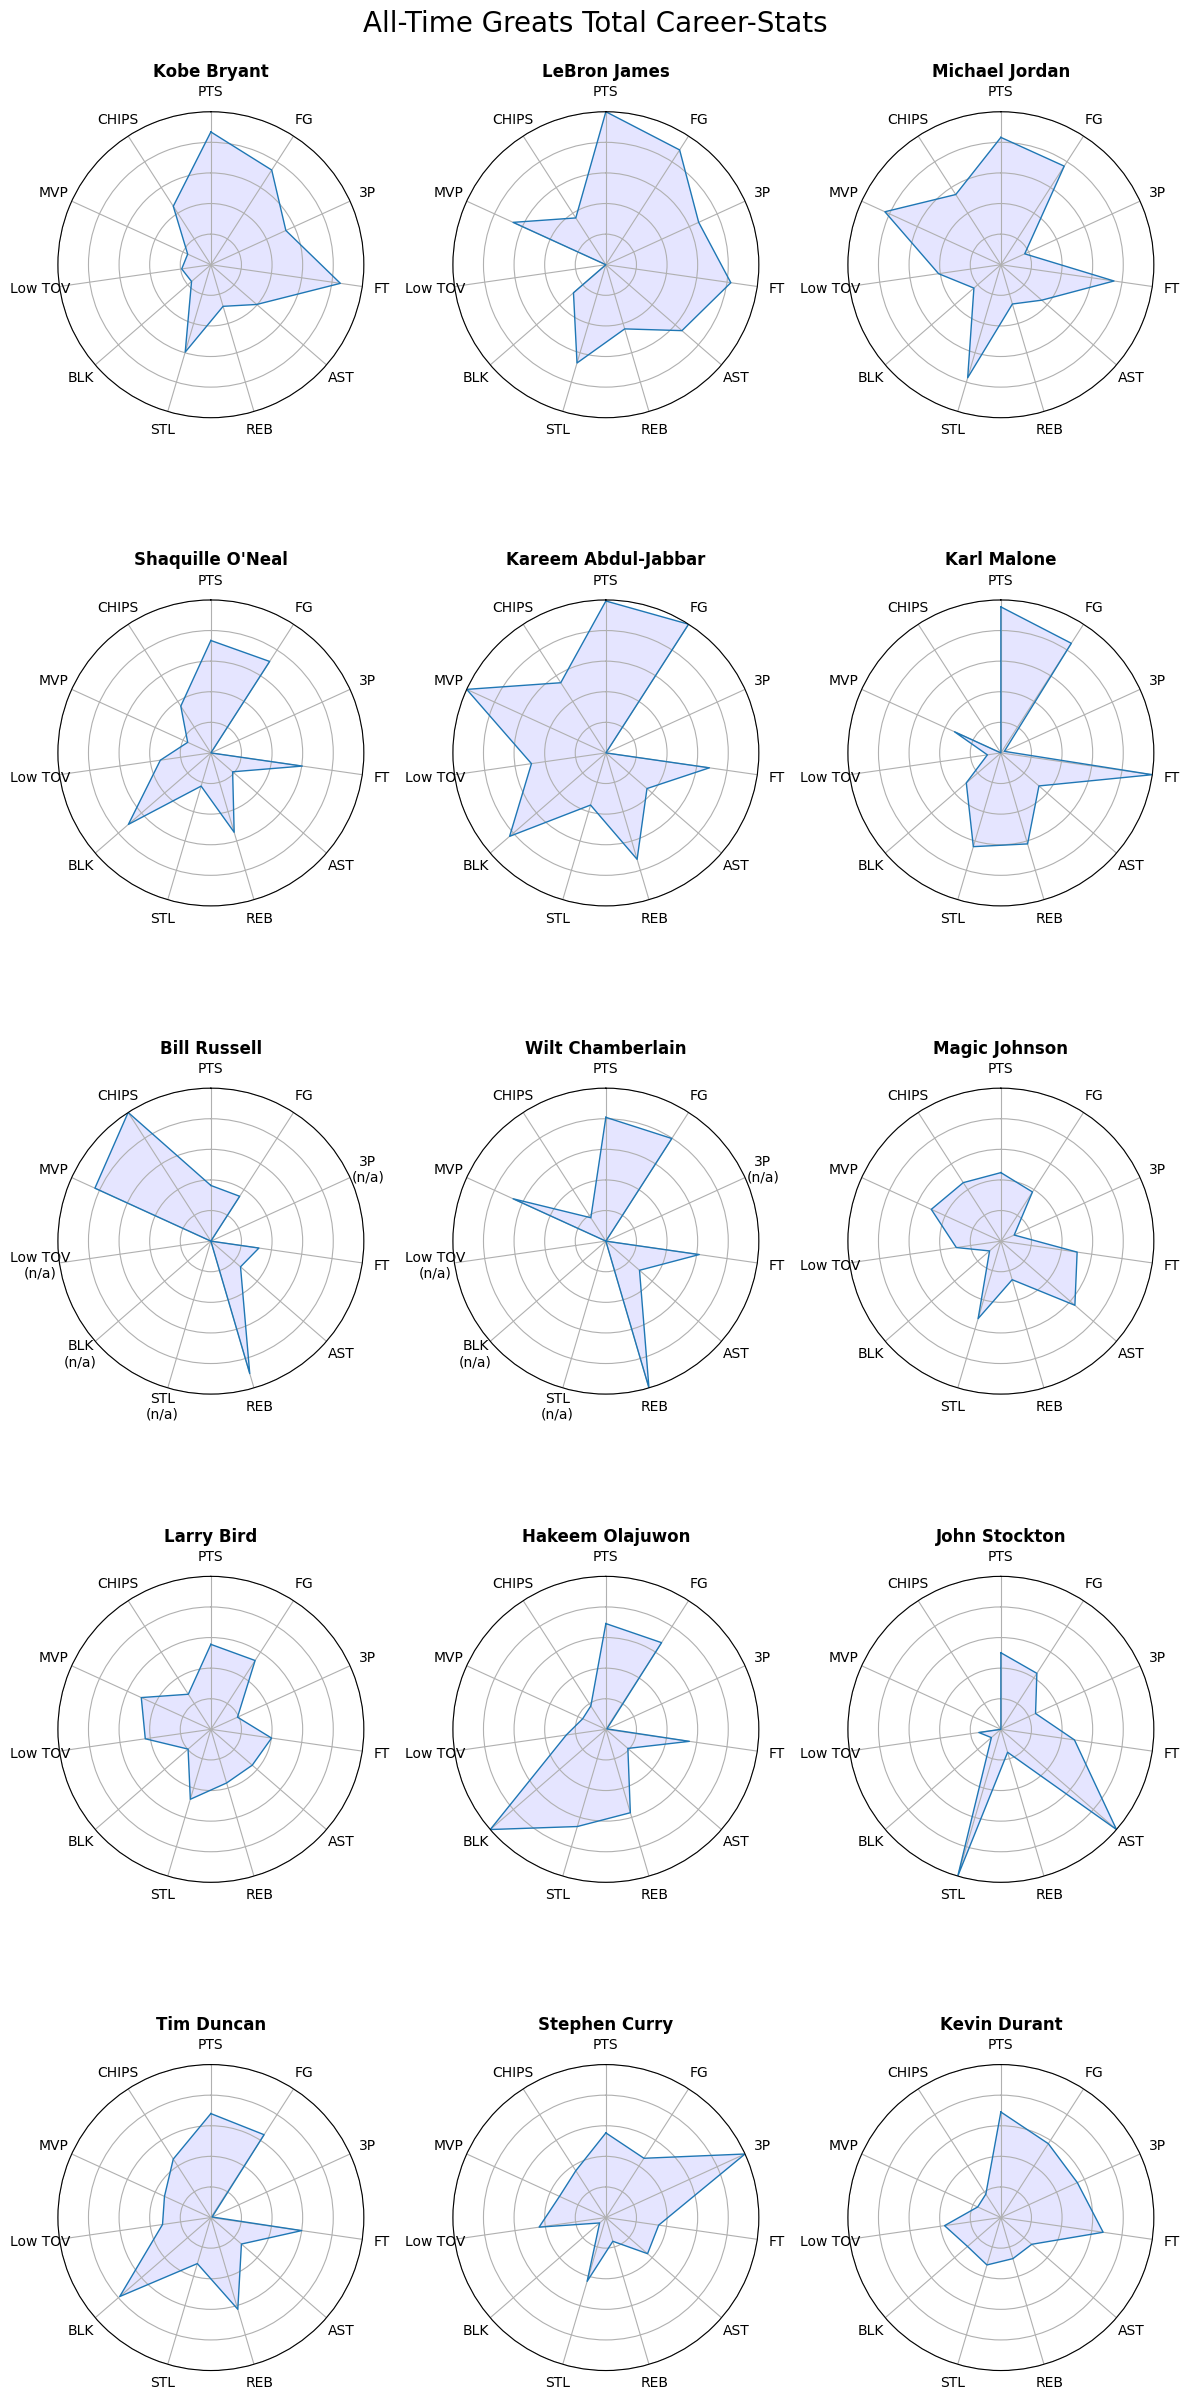

In [76]:
fig = plt.figure(figsize=(12, 25))
for i, player in enumerate(all_time_greats):
    ax = plt.subplot(5, 3, i + 1, polar=True)
    scaled_player_data = scaled_career_data.loc[scaled_career_data.Player == str(player)].copy()
    radar_factory(columns_names_shown,
                  list(scaled_player_data[career_data_columns].values[0]),
                  player, axes=ax, fontsize=10)
fig.suptitle('All-Time Greats Total Career-Stats', fontsize=20, fontweight='light')
fig.tight_layout() #removes empty space under title
plt.show()

#### Conclusion
Those plots are great to see where each of the all-time great players dominated during their careers. As a result, it is a great way to compare the unique career achievements when it comes to the different basketball statistics. However, they reward longevity and some players have played less games than the others, for example Michael Jordan retired twice in the middle of his career (missing most of the 1993-94 and 1994-95 seasons and three full seasons from 1998 to 2001). Also, the stats that were not recorded yet (`n/a`) make the plots of Bill Russell and Wilt Chamberlain smaller than their real impact. This is why, this visualization does not tell the whole story on who is the basketball greatest athlete. However these visualizations could show the greatest NBA career when it comes to longevity: Kareem Abdul-Jabbar and LeBron James have the most complete career plots, with Kareem leading in MVP awards, field goals, rebounds and blocks and LeBron in points, assists and steals. Notice that LeBron's `Low TOV` value is 0, since he has the most turnovers in NBA history.

### All time great players per game stats comparison
Next we will find the average stats per game for every player and save them in new columns. For 3-pointers, steals, blocks and turnovers we divide by the games played in the seasons where the statistic was recorded, so that e.g. the first seasons of Kareem Abdul-Jabbar (before blocks were recorded) do not lower his blocks per game:

In [77]:
column_names_pergame_stats = ['total_FG','total_3P','total_TRB','total_AST',
                             'total_STL','total_BLK','total_TOV','total_PTS','total_FT']
for attribute in column_names_pergame_stats:
    statistic = str(attribute).replace('total_','')
    if statistic in tracked_stats:
        games = career_data_minimum_standards['G_tracked_' + statistic]
    else:
        games = career_data_minimum_standards.G
    career_data_minimum_standards[statistic + '_pergame'] = career_data_minimum_standards[attribute] / games

One column that presents some problems is the 3-point percentage. Some players that shoot the ball very rarely have extremely high (or low) percentages for this attribute. We set the 3-point percentage of players that shot 50 or fewer threes in their career as empty, so it is shown as `n/a` (e.g. Kareem Abdul-Jabbar or Shaquille O'Neal)

In [78]:
career_data_minimum_standards.loc[career_data_minimum_standards['total_3PA'] <= 50, '3P%'] = np.nan

Next we scale the data that we are interested in and invert the turnovers again:

In [79]:
scaler = MinMaxScaler()

pergame_data_columns = ['PTS_pergame','FG_pergame','3P_pergame','FT_pergame','AST_pergame','TRB_pergame',
                    'STL_pergame','BLK_pergame',
                    'TOV_pergame', 'FT%','3P%','FG%'] #columns that we are interested

X = scaler.fit_transform(career_data_minimum_standards[pergame_data_columns]) #scaling data
scaled_pergame_data = pd.DataFrame(X, index=career_data_minimum_standards.index,
                             columns=pergame_data_columns) #creating a new dataframe
scaled_pergame_data['TOV_pergame'] = 1 - scaled_pergame_data['TOV_pergame'] #inverting turnovers, since fewer turnovers is better
scaled_pergame_data = scaled_pergame_data.join(career_data_minimum_standards.Player) #adding the player names

Now we can set the names of the attributes that will be shown

In [80]:
columns_names_shown = ['PTS','FG','3P','FT','AST','REB','STL','BLK',
                        'Low TOV','FT%','3P%','FG%']

Now we visualize the results:

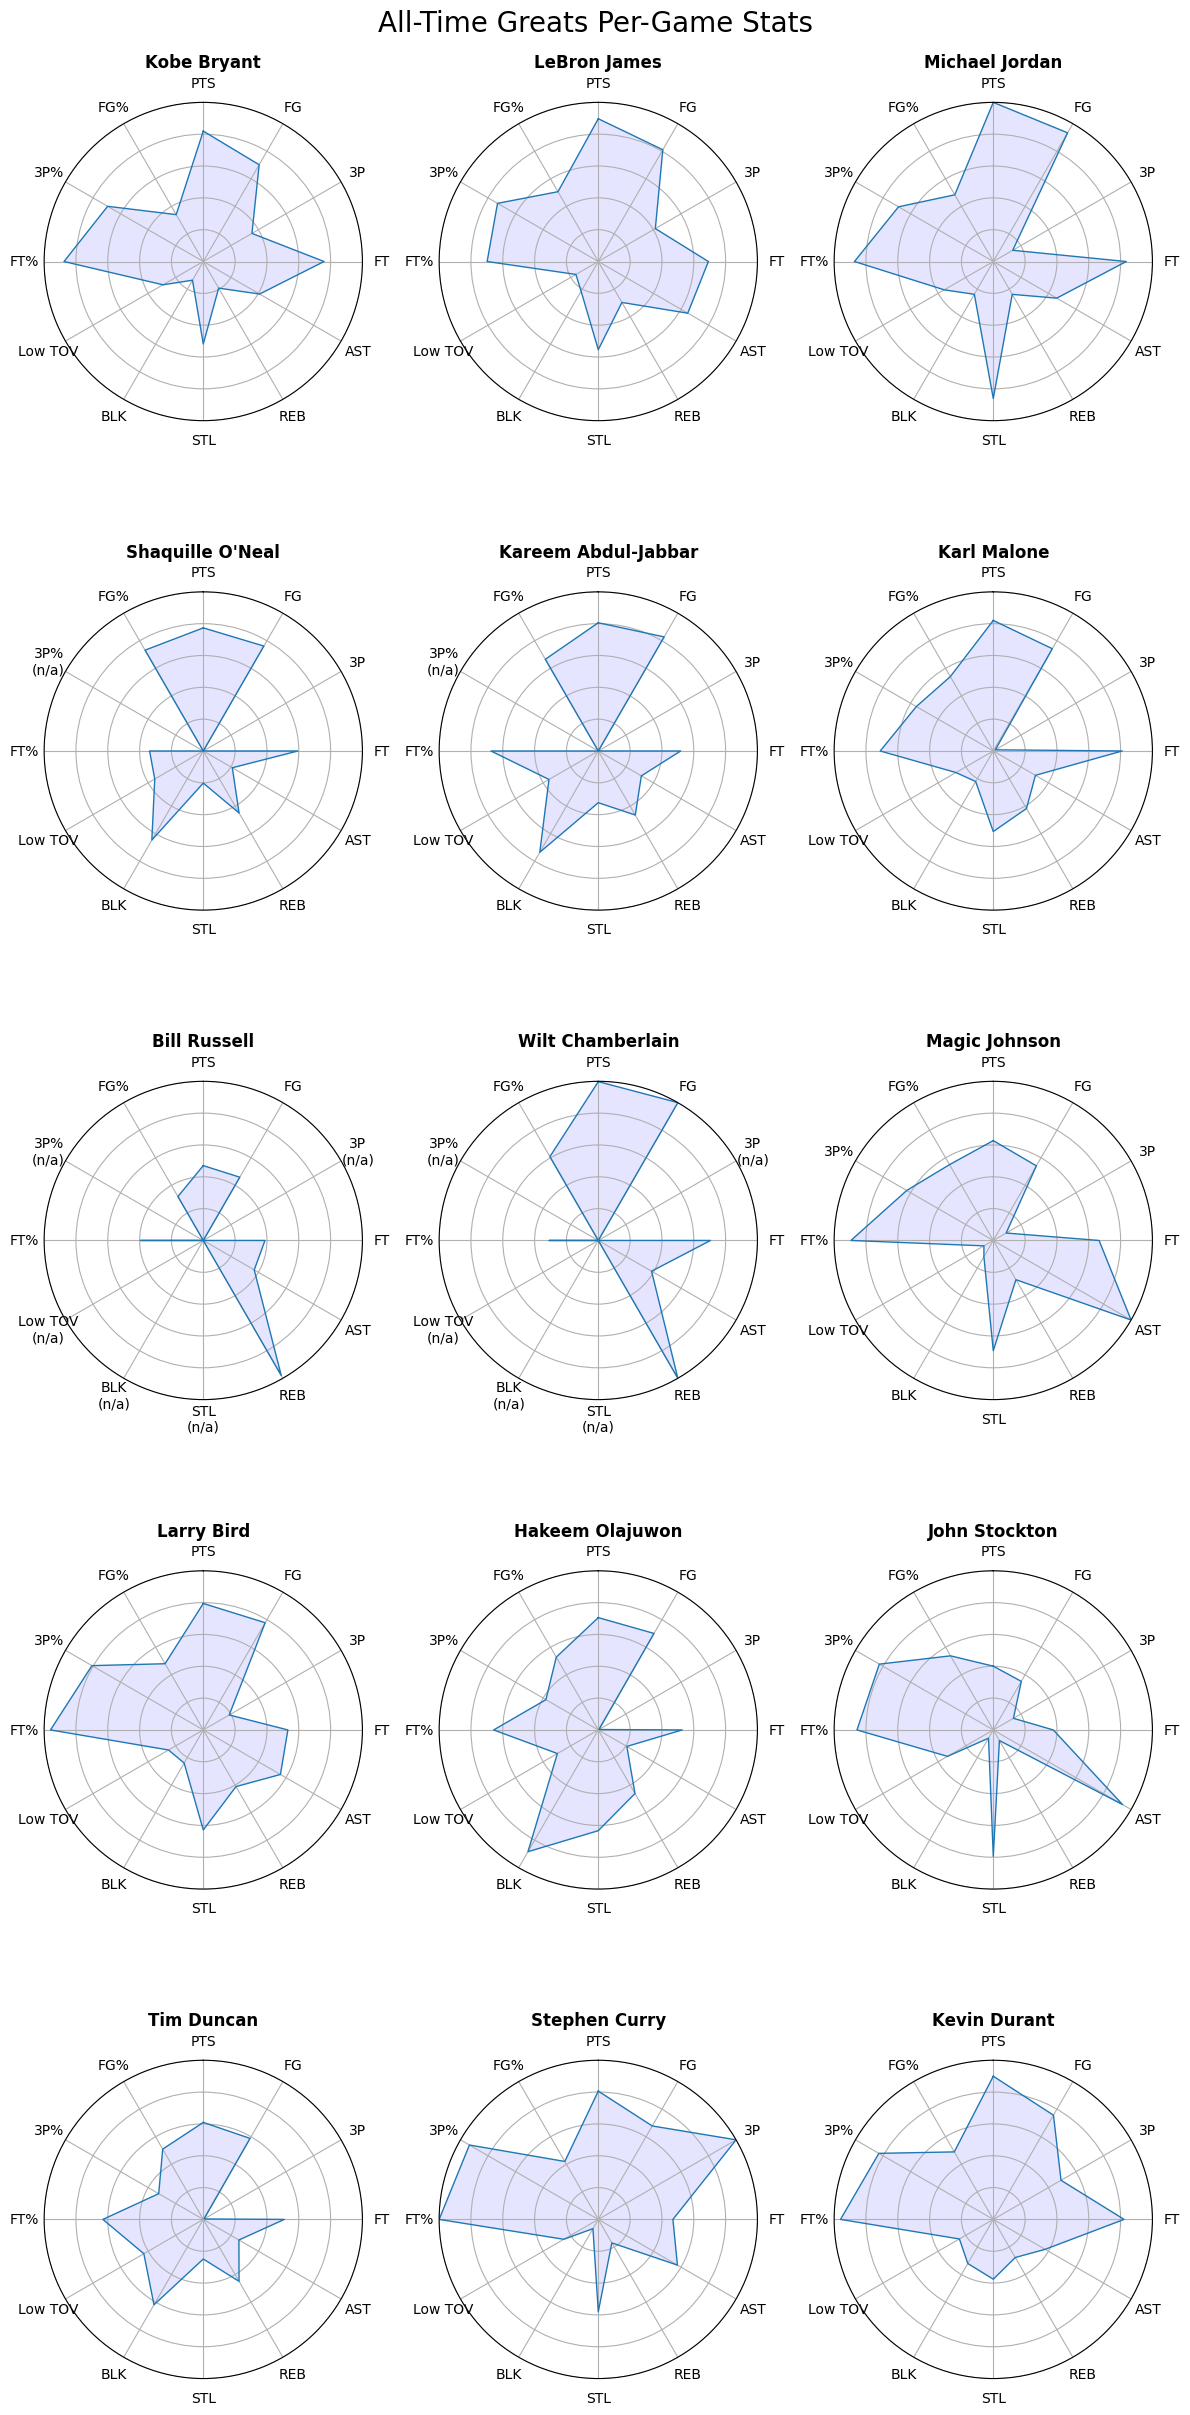

In [81]:
fig = plt.figure(figsize=(12, 25))
for i, player in enumerate(all_time_greats):
    ax = plt.subplot(5, 3, i + 1, polar=True)
    scaled_player_data = scaled_pergame_data.loc[scaled_pergame_data.Player == str(player)].copy()
    radar_factory(columns_names_shown,
                  list(scaled_player_data[pergame_data_columns].values[0]),
                  player, axes=ax, fontsize=10)
fig.suptitle('All-Time Greats Per-Game Stats', fontsize=20, fontweight='light')
fig.tight_layout() #removes empty space under title
plt.show()

#### Conclusions
This visualization is much better to see how each all-time great affected the games he played in. Of course due to the stats that were not recorded during the years of Bill Russell and Wilt Chamberlain (turnovers, steals, blocks and 3-pointers), we can not have the whole picture for them. Also, the shooting percentages (FT%, 3P%) favor the perimeter players, while the big men are favored by FG% and blocks, and the `Low TOV` axis penalizes the players that had the ball in their hands the most, like Magic Johnson and LeBron James. Players like Lebron, Durant, Kobe and Jordan have very similar plots since they played similar roles in their teams but have achieved different things in their careers. Michael Jordan has the most complete per-game plot of the group (the highest scoring average together with Wilt Chamberlain and the most steals per game), followed closely by Stephen Curry and Kevin Durant, whose plots get a boost from the shooting percentages. In conclusion, I believe it is impossible to only pick one player as the greatest of all time due to the plethora of factors and stats categories that exist, the difference of basketball eras and the impossibility of seeing the all-time greats compete against each other. However, combining both comparisons, it seems like Michael Jordan (the best per-game plot) and LeBron James (one of the best per-game plots and the most complete career after Kareem) are head-to-head the greatest basketball players of all time.